# EDS 6352 — Natural Language Processing | Assignment 4
## Sentiment Analysis Using Fine-Tuned BERT-base-uncased

**Ihina Mahajan | Fall 2026**

### Objective and experiment design

This notebook documents the complete IMDb sentiment classification experiment. Four BERT-base-uncased architectures are trained independently and evaluated on the original 400-review test set from Assignment 1.

- **Model 1:** standard BERT classifier, linear head.
- **Model 2:** BERT with a 256-unit ReLU classification head.
- **Model 3:** BERT with a 256-unit GELU classification head.
- **Model 4:** averages the `[CLS]` token embeddings from the final four transformer blocks and applies a linear head, selected from Models 1–3 using validation accuracy.

The original training outputs and figures are retained in this executed submission notebook.

**Reproducibility and submission note.** The complete training and evaluation source code is included. `movie.csv` must be available in the notebook's working directory, and the first run downloads or loads the pretrained Hugging Face `bert-base-uncased` resources. **Checkpoint files are not needed to read the results or inspect the submitted code.** A full **Restart & Run All** will fine-tune all four models again and may require several hours on CPU; that is expected, not necessary for reviewing the preserved outputs. Training checkpoints are saved locally for convenience but are not part of the submission. The stored timing measurements were made on the original CPU environment and will change across machines.

**Experimental caution.** Model 4 directly averages unpooled transformer-block `[CLS]` outputs, while Models 1–3 use the standard pooled BERT output. Therefore the Model 1 vs Model 4 comparison includes removing the pooler as well as averaging layers. All model choices are based on validation accuracy, not test accuracy.


In [1]:
# Common libraries used throughout the notebook
import html
import os
import time
import random
import re
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display

# Optional inspection packages present in the original environment
import math
from collections import Counter


In [2]:
pd.set_option("display.max_colwidth", 150)

## 1. Load and Inspect the Dataset

The file `movie.csv` is expected to be in the same folder as this notebook. I check the shape, columns, missing values and class distribution first.

In [3]:
data = pd.read_csv("movie.csv")
data.head()

,text,label
0,"I grew up (b. 1965) watching and loving the Thunderbirds. All my mates at school watched. We played ""Thunderbirds"" before school, during lunch and...",0
1,"When I put this movie in my DVD player, and sat down with a coke and some chips, I had some expectations. I was hoping that this movie would conta...",0
2,Why do people who do not know what a particular time in the past was like feel the need to try to define that time for others? Replace Woodstock w...,0
3,"Even though I have great interest in Biblical movies, I was bored to death every minute of the movie. Everything is bad. The movie is too long, th...",0
4,"Im a die hard Dads Army fan and nothing will ever change that. I got all the tapes, DVD's and audiobooks and every time i watch/listen to them its...",1


In [4]:
# Display the number of rows and columns
print("Dataset shape:", data.shape)

# Display column names
print("\nColumn names:")
print(data.columns.tolist())

# Check for missing values
print("\nMissing values:")
print(data.isnull().sum())

# Check the distribution of sentiment labels
print("\nSentiment distribution:")
print(data["label"].value_counts())

# Display the first five records
print("\nFirst five records:")
display(data.head())

Dataset shape: (40000, 2)

Column names:
['text', 'label']

Missing values:
text     0
label    0
dtype: int64

Sentiment distribution:
label
0    20019
1    19981
Name: count, dtype: int64

First five records:


,text,label
0,"I grew up (b. 1965) watching and loving the Thunderbirds. All my mates at school watched. We played ""Thunderbirds"" before school, during lunch and...",0
1,"When I put this movie in my DVD player, and sat down with a coke and some chips, I had some expectations. I was hoping that this movie would conta...",0
2,Why do people who do not know what a particular time in the past was like feel the need to try to define that time for others? Replace Woodstock w...,0
3,"Even though I have great interest in Biblical movies, I was bored to death every minute of the movie. Everything is bad. The movie is too long, th...",0
4,"Im a die hard Dads Army fan and nothing will ever change that. I got all the tapes, DVD's and audiobooks and every time i watch/listen to them its...",1


In [5]:
# Check for duplicate reviews
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate review texts:", data.duplicated(subset=["text"]).sum())

Duplicate rows: 277
Duplicate review texts: 277


In [6]:
# Remove Missing Values and Duplicates
data = data.dropna(subset=["text", "label"])
data = data.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Shape after cleaning:", data.shape)
print("Missing values left:", data.isnull().sum().sum())
print("Duplicate reviews left:", data.duplicated(subset=["text"]).sum())

Shape after cleaning: (39723, 2)
Missing values left: 0
Duplicate reviews left: 0


## Sampling the Training and Test Data

The same 1,000 training and 400 test reviews from Homework 1 are retained.

The original training set is further divided into 80% training and 20% validation data using stratified sampling. This preserves the distribution of positive and negative reviews.

The same training and validation subsets will be used for all four BERT models. The original 400 test reviews remain unchanged for final evaluation.

In [8]:
# Recreate Assignment 1 sampling using the *already cleaned* DataFrame.
# This matches the sampling function in Mahajan_HW1_1.ipynb.
# The seed and sample order must not be changed when reproducing the experiment.

# Use the exact sampling function from Assignment 1
def create_train_test_split(
    data,
    train_size=1000,
    test_per_class=200,
    seed=42
):

    rng = random.Random(seed)

    # Randomly select 1000 training reviews
    all_indices = list(data.index)
    rng.shuffle(all_indices)

    train_indices = all_indices[:train_size]

    # Remaining reviews are eligible for testing
    remaining_indices = all_indices[train_size:]

    negative_indices = [
        i for i in remaining_indices
        if data.loc[i, "label"] == 0
    ]

    positive_indices = [
        i for i in remaining_indices
        if data.loc[i, "label"] == 1
    ]

    rng.shuffle(negative_indices)
    rng.shuffle(positive_indices)

    # Select 200 reviews from each class
    test_indices = (
        negative_indices[:test_per_class]
        + positive_indices[:test_per_class]
    )

    rng.shuffle(test_indices)

    train_data = data.loc[train_indices].copy()
    test_data = data.loc[test_indices].copy()

    return train_data, test_data


# Create the original Assignment 1 split
train_data, test_data = create_train_test_split(data)

print("Cleaned dataset:", data.shape)
print("Original training set:", train_data.shape)
print("Original test set:", test_data.shape)

print("\nTest label distribution:")
print(test_data["label"].value_counts().sort_index())


Cleaned dataset: (39723, 2)
Original training set: (1000, 2)
Original test set: (400, 2)

Test label distribution:
label
0    200
1    200
Name: count, dtype: int64


In [9]:
# Split the original training set into 80% training and 20% validation, maintaining the class balance.
train_df, val_df = train_test_split(
    train_data,
    test_size=0.20,
    random_state=42,
    stratify=train_data["label"]
)

# Preserve the original Homework 1 test set
test_df = test_data.copy()

# Display dataset sizes
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

# Check the number of positive and negative reviews
print("\nTraining labels:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation labels:")
print(val_df["label"].value_counts().sort_index())

print("\nTesting labels:")
print(test_df["label"].value_counts().sort_index())

# Verify that there are no shared reviews
assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)

print("\nNo overlapping reviews.")

Training: (800, 2)
Validation: (200, 2)
Testing: (400, 2)

Training labels:
label
0    400
1    400
Name: count, dtype: int64

Validation labels:
label
0    100
1    100
Name: count, dtype: int64

Testing labels:
label
0    200
1    200
Name: count, dtype: int64

No overlapping reviews.


### Inspecting Text Before Cleaning

Before applying text cleaning, the movie reviews are examined for HTML tags, line breaks, and other unwanted formatting characters.

Unlike traditional machine learning approaches, BERT does not require lemmatization, stop-word removal, or explicit negation handling.

Punctuation and the original word forms will be preserved because they provide useful contextual information for the pretrained language model.

In [10]:
# Combine the training, validation, and test reviews for inspection only (not for model training)

all_reviews = pd.concat(
    [train_df["text"], val_df["text"], test_df["text"]]
)

# Count common formatting characters
patterns = {
    "HTML line breaks": r"<br\s*/?>",
    "Other HTML tags": r"<(?!br\s*/?>)[^>]+>",
    "Newline characters": r"\n",
    "Tab characters": r"\t",
    "Repeated spaces": r" {2,}"
}

print("Special character counts:\n")

for name, pattern in patterns.items():
    count = all_reviews.str.contains(
        pattern, regex=True, case=False
    ).sum()

    print(f"{name}: {count} reviews")

# Display examples containing HTML line breaks
html_examples = all_reviews[
    all_reviews.str.contains(
        r"<br\s*/?>", regex=True, case=False
    )
]

print("\nExamples of reviews containing HTML line breaks:\n")

for review in html_examples.head(3):
    print(repr(review[:350]))
    print("-" * 60)

Special character counts:

HTML line breaks: 817 reviews
Other HTML tags: 1 reviews
Newline characters: 0 reviews
Tab characters: 0 reviews
Repeated spaces: 0 reviews

Examples of reviews containing HTML line breaks:

'I just found the entire 3 DVD set at Wal-Mart in the bargain bin for $5.50, so I thought I would take another look. Total of 13 hours to watch it all (26 episodes). I was born in 1948 and saw most of them on TV in the sixties. Many independent stations repeated them for many years.<br /><br />Better than I expected actually, time has been kind to t'
------------------------------------------------------------
'A trio of low-life criminals, led by Matt Dillon, botches a late-night burglary. They flee but quickly cross paths with the police who just happen to be in hot pursuit of a terrorist. Of course the police mistake the burglar gang for the terrorist, the real terrorist gets away, and the burglars are forced to take refuge in a small dive of a bar, ta'
---------------

### Text Cleaning for BERT

The movie reviews are cleaned by replacing HTML line breaks with appropriate sentence boundaries, removing remaining HTML tags, and normalizing whitespace.

Existing punctuation is preserved. Where a line break separates text without sentence-ending punctuation, a period is inserted to preserve the sentence boundary.

Unlike Homework 1, no lemmatization, stop-word removal, stemming, or explicit negation handling is performed. Lowercasing will be handled automatically by the BERT-base-uncased tokenizer.

The same cleaning procedure is applied independently to the training, validation, and test datasets.


In [13]:
import html

# Improved cleaning function for BERT
def clean_review(text):

    # Convert HTML entities into regular characters
    text = html.unescape(str(text))

    # Replace consecutive HTML line breaks with a sentence boundary.
    # Preserve an existing period, question mark, or exclamation mark.
    text = re.sub(
        r"([.!?])\s*(?:<br\s*/?>\s*)+",
        r"\1 ",
        text,
        flags=re.IGNORECASE
    )

    # Insert a period where an HTML break separates text
    # without existing sentence-ending punctuation.
    text = re.sub(
        r"(?:<br\s*/?>\s*)+",
        ". ",
        text,
        flags=re.IGNORECASE
    )

    # Remove any remaining HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Replace actual newline characters with spaces
    text = re.sub(r"[\r\n\t]+", " ", text)

    # Normalize extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Reapply the corrected cleaning function
train_df["text_clean"] = train_df["text"].apply(clean_review)
val_df["text_clean"] = val_df["text"].apply(clean_review)
test_df["text_clean"] = test_df["text"].apply(clean_review)

# Verify cleaning
print("Training reviews:", len(train_df))
print("Validation reviews:", len(val_df))
print("Test reviews:", len(test_df))

print("\nCleaning example:")
print(clean_review("Good movie<br /><br />But the ending was bad."))


Training reviews: 800
Validation reviews: 200
Test reviews: 400

Cleaning example:
Good movie. But the ending was bad.


In [14]:
# Compare an original review with its cleaned version
example = train_df[
    train_df["text"].str.contains(
        r"<br\s*/?>", regex=True, case=False
    )
].iloc[0]

print("ORIGINAL REVIEW:\n")
print(example["text"][:500])

print("\n" + "=" * 60)

print("\nCLEANED REVIEW:\n")
print(example["text_clean"][:500])

ORIGINAL REVIEW:

I just found the entire 3 DVD set at Wal-Mart in the bargain bin for $5.50, so I thought I would take another look. Total of 13 hours to watch it all (26 episodes). I was born in 1948 and saw most of them on TV in the sixties. Many independent stations repeated them for many years.<br /><br />Better than I expected actually, time has been kind to the obvious sincerity of it's creators, and to the obvious gratitude and respect they give to all the Allied fighting men and women. More abstract and 


CLEANED REVIEW:

I just found the entire 3 DVD set at Wal-Mart in the bargain bin for $5.50, so I thought I would take another look. Total of 13 hours to watch it all (26 episodes). I was born in 1948 and saw most of them on TV in the sixties. Many independent stations repeated them for many years. Better than I expected actually, time has been kind to the obvious sincerity of it's creators, and to the obvious gratitude and respect they give to all the Allied fighting men an

## BERT Tokenization

The `BertTokenizerFast` tokenizer from Hugging Face is used with the pretrained `bert-base-uncased` model.

The tokenizer converts movie reviews into tokens and their corresponding numerical IDs. It also adds special tokens such as `[CLS]` and `[SEP]`, which are required by BERT.

Since the selected model is uncased, the tokenizer is expected to convert uppercase letters to lowercase automatically. This behavior is verified using sample sentences before tokenizing the dataset.

In [15]:
# Load BERT Tokenizer and Verify Lowercasing


from transformers import BertTokenizerFast

# Load the pretrained BERT-base-uncased tokenizer
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

# Test sentences containing uppercase and mixed-case words
sample_texts = [
    "This Movie Was AMAZING!",
    "I did NOT like this movie.",
    "The ACTING was GREAT, but the STORY was terrible."
]

# Display the original text and its tokens
for text in sample_texts:

    tokens = tokenizer.tokenize(text)

    print("Original text:", text)
    print("BERT tokens:", tokens)
    print("-" * 60)

# Check whether the tokenizer automatically lowercases text
print("\nTokenizer lowercasing enabled:", tokenizer.do_lower_case)

C:\Users\imahaja2\AppData\Local\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Original text: This Movie Was AMAZING!
BERT tokens: ['this', 'movie', 'was', 'amazing', '!']
------------------------------------------------------------
Original text: I did NOT like this movie.
BERT tokens: ['i', 'did', 'not', 'like', 'this', 'movie', '.']
------------------------------------------------------------
Original text: The ACTING was GREAT, but the STORY was terrible.
BERT tokens: ['the', 'acting', 'was', 'great', ',', 'but', 'the', 'story', 'was', 'terrible', '.']
------------------------------------------------------------

Tokenizer lowercasing enabled: True


### Examining BERT Input Representations

The BERT tokenizer converts each review into numerical token IDs and an attention mask.

Two special tokens are added automatically:
- `[CLS]`: Placed at the beginning of the sequence. Its output representation is used for sentiment classification.
- `[SEP]`: Marks the end of the input sequence.

The attention mask identifies which token positions contain actual input tokens and which positions are padding.

A sample review is tokenized to inspect these representations before processing the complete dataset.

In [16]:
# Examine BERT Input IDs and Attention Masks

# A sample review for understanding BERT tokenization
sample_review = "I did NOT like this movie. The ending was terrible!"

# Tokenize the review and convert tokens to numerical IDs
encoded = tokenizer(
    sample_review,
    add_special_tokens=True,
    padding="max_length",
    truncation=True,
    max_length=20,
    return_attention_mask=True
)

# Convert numerical IDs back into readable tokens
tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])

print("Original review:")
print(sample_review)

print("\nBERT tokens:")
print(tokens)

print("\nInput IDs:")
print(encoded["input_ids"])

print("\nAttention mask:")
print(encoded["attention_mask"])

print("\nNumber of tokens:", sum(encoded["attention_mask"]))

Original review:
I did NOT like this movie. The ending was terrible!

BERT tokens:
['[CLS]', 'i', 'did', 'not', 'like', 'this', 'movie', '.', 'the', 'ending', 'was', 'terrible', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']

Input IDs:
[101, 1045, 2106, 2025, 2066, 2023, 3185, 1012, 1996, 4566, 2001, 6659, 999, 102, 0, 0, 0, 0, 0, 0]

Attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]

Number of tokens: 14


### Analysis of Review Token Lengths

The distribution of tokenized review lengths is examined to determine an appropriate maximum sequence length for BERT.

Although BERT-base supports sequences of up to 512 tokens, using shorter sequences can reduce training time and memory consumption.

Review lengths are calculated using the BERT tokenizer, including the special [CLS] and [SEP] tokens. The distribution and truncation percentages at different sequence lengths are compared before selecting the final maximum length.

In [17]:
# Analyze Token Lengths of Movie Reviews

# Combine reviews from all three datasets for length inspection.
# This does not modify the datasets or train the model.
all_texts = pd.concat([
    train_df["text_clean"],
    val_df["text_clean"],
    test_df["text_clean"]
])

# Tokenize all reviews without truncation or padding.
# Include [CLS] and [SEP] in the token counts.
encoded_reviews = tokenizer(
    all_texts.tolist(),
    add_special_tokens=True,
    truncation=False,
    padding=False
)

# Calculate the token length of every review
token_lengths = np.array([
    len(ids) for ids in encoded_reviews["input_ids"]
])

# Display summary statistics
print("Total reviews:", len(token_lengths))
print("Minimum token length:", token_lengths.min())
print("Maximum token length:", token_lengths.max())
print("Mean token length:", round(token_lengths.mean(), 2))
print("Median token length:", np.median(token_lengths))

print("\nToken length percentiles:")
for percentile in [75, 90, 95, 99]:
    print(
        f"{percentile}th percentile:",
        np.percentile(token_lengths, percentile)
    )

# Determine the percentage of reviews requiring truncation
print("\nPercentage of reviews exceeding different lengths:")

for max_len in [128, 256, 384, 512]:
    percentage = (token_lengths > max_len).mean() * 100
    print(f"Length {max_len}: {percentage:.2f}%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (773 > 512). Running this sequence through the model will result in indexing errors


Total reviews: 1400
Minimum token length: 26
Maximum token length: 1325
Mean token length: 288.61
Median token length: 217.5

Token length percentiles:
75th percentile: 353.25
90th percentile: 560.2000000000003
95th percentile: 730.0999999999999
99th percentile: 1095.1499999999999

Percentage of reviews exceeding different lengths:
Length 128: 86.93%
Length 256: 40.21%
Length 384: 20.79%
Length 512: 12.50%


### Tokenization of Training, Validation, and Test Data

Based on the token length distribution, a maximum sequence length of 384 tokens is selected as a compromise between retaining review content and computational efficiency.

The cleaned reviews are encoded using `BertTokenizerFast`. Truncation is applied to reviews exceeding the maximum length, and shorter reviews are padded to a uniform length.

The tokenizer generates input IDs and attention masks required by BERT. The same tokenization settings are used for the training, validation, and test datasets and for all four models.

In [18]:
# Tokenize Training, Validation, and Test Reviews

# Maximum number of tokens per review, including special tokens
MAX_LENGTH = 384

# Tokenize training reviews
train_encodings = tokenizer(
    train_df["text_clean"].tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_attention_mask=True
)

# Tokenize validation reviews using identical settings
val_encodings = tokenizer(
    val_df["text_clean"].tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_attention_mask=True
)

# Tokenize test reviews using identical settings
test_encodings = tokenizer(
    test_df["text_clean"].tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_attention_mask=True
)

# Verify the number of reviews and sequence lengths
print("Training reviews:", len(train_encodings["input_ids"]))
print("Validation reviews:", len(val_encodings["input_ids"]))
print("Test reviews:", len(test_encodings["input_ids"]))

print("\nSequence lengths:")
print("Training:", len(train_encodings["input_ids"][0]))
print("Validation:", len(val_encodings["input_ids"][0]))
print("Test:", len(test_encodings["input_ids"][0]))

# Confirm that all input sequences have the expected length
assert all(len(x) == MAX_LENGTH for x in train_encodings["input_ids"])
assert all(len(x) == MAX_LENGTH for x in val_encodings["input_ids"])
assert all(len(x) == MAX_LENGTH for x in test_encodings["input_ids"])

print("\nTokenization completed successfully.")


Training reviews: 800
Validation reviews: 200
Test reviews: 400

Sequence lengths:
Training: 384
Validation: 384
Test: 384

Tokenization completed successfully.


## Preparing Data for PyTorch

The tokenized movie reviews are converted into PyTorch tensors for model training and evaluation.

Each example contains three components:

- `input_ids`: Numerical token IDs generated by the BERT tokenizer.
- `attention_mask`: Identifies valid tokens and padding positions.
- `labels`: Binary sentiment labels (0 for negative and 1 for positive).

A custom PyTorch Dataset class is created to organize these components and allow efficient loading of examples during fine-tuning.

The same Dataset class is used for the training, validation, and test sets.


In [19]:
import torch
from torch.utils.data import Dataset

# Custom Dataset class for BERT sentiment classification
class MovieReviewDataset(Dataset):

    def __init__(self, encodings, labels):

        # Store tokenized reviews and their sentiment labels
        self.encodings = encodings
        self.labels = labels

    def __len__(self):

        # Return the total number of reviews
        return len(self.labels)

    def __getitem__(self, idx):

        # Convert the tokenized inputs to PyTorch tensors
        item = {
            key: torch.tensor(values[idx], dtype=torch.long)
            for key, values in self.encodings.items()
        }

        # Add the correct sentiment label
        item["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )

        return item


# Create datasets using the tokenized inputs and actual labels
train_dataset = MovieReviewDataset(
    train_encodings,
    train_df["label"].tolist()
)

val_dataset = MovieReviewDataset(
    val_encodings,
    val_df["label"].tolist()
)

test_dataset = MovieReviewDataset(
    test_encodings,
    test_df["label"].tolist()
)

# Verify dataset sizes
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

# Inspect one training example
sample = train_dataset[0]

print("\nFirst training example:")
print("Input IDs shape:", sample["input_ids"].shape)
print("Attention mask shape:", sample["attention_mask"].shape)
print("Sentiment label:", sample["labels"].item())

print("\nPyTorch datasets created successfully.")


Training dataset: 800
Validation dataset: 200
Test dataset: 400

First training example:
Input IDs shape: torch.Size([384])
Attention mask shape: torch.Size([384])
Sentiment label: 1

PyTorch datasets created successfully.


### Computational Environment

Before fine-tuning BERT, the computational environment is examined to determine whether GPU acceleration is available.

PyTorch supports model training on both CPUs and compatible GPUs. GPU acceleration is particularly useful for transformer models because of their computational complexity.

The available device, PyTorch version, and CUDA availability are checked to determine appropriate training settings.

In [20]:
# Display the installed PyTorch version
print("PyTorch version:", torch.__version__)

# Check whether CUDA-compatible GPU acceleration is available
print("CUDA available:", torch.cuda.is_available())

# Select the appropriate device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

# Display GPU information if CUDA is available
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        )
    )
else:
    print("No CUDA GPU detected. PyTorch will use the CPU.")


PyTorch version: 2.12.1+cpu
CUDA available: False
Selected device: cpu
No CUDA GPU detected. PyTorch will use the CPU.


### Training Configuration and Reproducibility

The same training configuration is used for all four BERT models to ensure a consistent comparison.

A fixed random seed is set to improve reproducibility. The initial training configuration uses the AdamW optimizer, a learning rate of 2e-5, a batch size of 8, and 3 training epochs.

The maximum sequence length is fixed at 384 tokens for all models.

Since the local environment currently uses a CPU-only PyTorch installation, GPU acceleration is recommended for computationally intensive fine-tuning.

In [21]:
# Fixed random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set CUDA seed if a GPU is available
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training hyperparameters
BATCH_SIZE = 8
LEARNING_RATE = 2e-5
NUM_EPOCHS = 3

# Maximum sequence length was selected previously
MAX_LENGTH = 384

# Print the training configuration
print("Random seed:", SEED)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Number of epochs:", NUM_EPOCHS)
print("Maximum sequence length:", MAX_LENGTH)
print("Training device:", device)

Random seed: 42
Batch size: 8
Learning rate: 2e-05
Number of epochs: 3
Maximum sequence length: 384
Training device: cpu


### Creating PyTorch DataLoaders

PyTorch DataLoaders are created to organize the tokenized datasets into batches for model training and evaluation.

A batch size of 8 is used for all models. Training data is shuffled to vary the order of examples during fine-tuning, while validation and test data are kept in a fixed order.

The same DataLoaders will be used consistently across all four BERT classification models.

In [22]:
from torch.utils.data import DataLoader

# Training DataLoader: shuffle reviews during training
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Validation DataLoader: keep the order fixed
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Test DataLoader: keep the order fixed
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Display the number of batches in each dataset
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# Inspect one batch from the training DataLoader
batch = next(iter(train_loader))

print("\nFirst training batch:")
print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)

print("\nDataLoaders created successfully.")


Training batches: 100
Validation batches: 25
Testing batches: 50

First training batch:
Input IDs shape: torch.Size([8, 384])
Attention mask shape: torch.Size([8, 384])
Labels shape: torch.Size([8])

DataLoaders created successfully.


## BERT Model Development

### Model 1: Linear Classification Head

The first model uses the pretrained `bert-base-uncased` architecture with a linear classification head.

The model is loaded using Hugging Face's `BertForSequenceClassification` class. It consists of 12 transformer encoder blocks, followed by a pooled [CLS] representation and a linear classification layer.

The classification layer maps the 768-dimensional BERT representation to two output logits, corresponding to negative and positive sentiment.

No additional hidden layer is used in the classification head.

Both the pretrained BERT encoder and the classification head will be fine-tuned using the training dataset.

In [29]:
from transformers import BertForSequenceClassification

# Load pretrained BERT with a two-class classification head.
# The classification head has no additional hidden layer.
model1 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2,
    id2label={0: "Negative", 1: "Positive"},
    label2id={"Negative": 0, "Positive": 1}
)

# Move the model to the available device (CPU or GPU)
model1 = model1.to(device)

# Examine the classifier architecture
print("Model 1 classification head:")
print(model1.classifier)

# Check the input and output dimensions
print("\nInput features:", model1.classifier.in_features)
print("Output features:", model1.classifier.out_features)

# Count all model parameters
total_params = sum(p.numel() for p in model1.parameters())

# Count parameters that will be updated during fine-tuning
trainable_params = sum(
    p.numel() for p in model1.parameters() if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("\nModel 1 initialized successfully.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3697.35it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Model 1 classification head:
Linear(in_features=768, out_features=2, bias=True)

Input features: 768
Output features: 2

Total parameters: 109,483,778
Trainable parameters: 109,483,778

Model 1 initialized successfully.


### Training Configuration

The AdamW optimizer is used to fine-tune Model 1.

AdamW adapts parameter updates using estimates of the first and second moments of the gradients and applies decoupled weight decay for regularization.

A learning rate of 2e-5 is selected for fine-tuning. All parameters of the pretrained BERT encoder and the newly initialized classification head are trainable.

The model will use cross-entropy loss for binary sentiment classification with two output logits.

In [30]:
#  Configure Optimizer for Model 1

from torch.optim import AdamW

# Initialize AdamW optimizer for all trainable parameters
optimizer1 = AdamW(
    model1.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# Display optimizer settings
print("Optimizer: AdamW")
print("Learning rate:", optimizer1.param_groups[0]["lr"])
print("Weight decay:", optimizer1.param_groups[0]["weight_decay"])

# Verify that BERT and classifier weights are trainable
print("\nBERT trainable:", model1.bert.embeddings.word_embeddings.weight.requires_grad)
print("Classifier trainable:", model1.classifier.weight.requires_grad)

print("\nOptimizer initialized successfully.")


Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.01

BERT trainable: True
Classifier trainable: True

Optimizer initialized successfully.


### Training Function

A reusable training function is defined to fine-tune BERT using the training DataLoader.

For each batch, the input IDs, attention masks, and sentiment labels are passed to the model. The cross-entropy classification loss is calculated, followed by backpropagation and parameter updates using the AdamW optimizer.

The average training loss and classification accuracy are calculated over one epoch. Training time is also recorded for comparison with the Naïve Bayes classifier from Homework 1.

The same training procedure will be used consistently for all four BERT models.

In [31]:
import time

def train_one_epoch(model, data_loader, optimizer, device):

    # Enable training mode (activates dropout)
    model.train()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Record the starting time of the epoch
    start_time = time.perf_counter()

    # Iterate over batches of training reviews
    for batch in data_loader:

        # Move the input tensors and labels to the selected device
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear gradients from the previous training step
        optimizer.zero_grad()

        # Forward pass: calculate logits and cross-entropy loss
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        # Backpropagation: calculate gradients
        loss.backward()

        # Update the model parameters
        optimizer.step()

        # Accumulate loss, weighted by batch size
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        # Convert classification logits into predicted class labels
        predictions = torch.argmax(logits, dim=1)

        # Count correct predictions
        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    # Compute average loss and accuracy over the full epoch
    average_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples

    # Measure elapsed training time
    elapsed_time = time.perf_counter() - start_time

    return average_loss, accuracy, elapsed_time


print("Training function defined successfully.")


Training function defined successfully.


### Validation Function

A validation function is defined to evaluate model performance on the validation dataset after each training epoch.

The model is switched to evaluation mode, which disables dropout. Gradient calculations are disabled because model parameters are not updated during validation.

The function calculates the average validation loss and classification accuracy. These metrics are used to monitor generalization and select the best-performing model.

Validation performance, rather than test performance, will be used to select the classification architecture for Model 4.

In [32]:
# BERT Validation Function

def evaluate_model(model, data_loader, device):

    # Switch to evaluation mode (disables dropout)
    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Disable gradients during evaluation
    with torch.no_grad():

        # Process the validation data one batch at a time
        for batch in data_loader:

            # Move inputs and labels to the selected device
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            # Forward pass without updating model parameters
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            # Calculate the number of examples in the batch
            batch_size = labels.size(0)

            # Accumulate loss, weighted by batch size
            total_loss += loss.item() * batch_size

            # Obtain predicted sentiment labels
            predictions = torch.argmax(logits, dim=1)

            # Count correctly classified reviews
            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    # Calculate average loss and accuracy
    average_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples

    return average_loss, accuracy


print("Validation function defined successfully.")


Validation function defined successfully.


### Fine-Tuning Model 1

Model 1 is fine-tuned for three epochs using the training dataset.

After each epoch, the model is evaluated on the validation dataset. Training loss, training accuracy, validation loss, and validation accuracy are recorded to monitor learning and generalization.

The checkpoint with the highest validation accuracy is retained. If two epochs have the same validation accuracy, the checkpoint with the lower validation loss is selected.

The total fine-tuning time is recorded for comparison with the Naïve Bayes classifier from Homework 1.

In [33]:
# Fine-Tune Model 1

import copy

# Store training history for Model 1
history1 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy1 = -1.0
best_val_loss1 = float("inf")
best_epoch1 = 0
best_weights1 = None

# Measure the total training and validation time
start_time1 = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

    # Train the model for one epoch
    train_loss, train_accuracy, epoch_time = train_one_epoch(
        model1,
        train_loader,
        optimizer1,
        device
    )

    # Evaluate the model on the validation dataset
    val_loss, val_accuracy = evaluate_model(
        model1,
        val_loader,
        device
    )

    # Record results for this epoch
    history1["train_loss"].append(train_loss)
    history1["train_accuracy"].append(train_accuracy)
    history1["val_loss"].append(val_loss)
    history1["val_accuracy"].append(val_accuracy)

    # Save the best-performing checkpoint in memory
    if (
        val_accuracy > best_val_accuracy1
        or (
            val_accuracy == best_val_accuracy1
            and val_loss < best_val_loss1
        )
    ):
        best_val_accuracy1 = val_accuracy
        best_val_loss1 = val_loss
        best_epoch1 = epoch + 1

        # Copy weights to CPU so the checkpoint is independent
        # of future parameter updates
        best_weights1 = {
            name: value.detach(  ).cpu().clone()
            for name, value in model1.state_dict().items()
        }

    # Display training progress
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Epoch Training Time: {epoch_time:.2f} seconds")

# Record the total elapsed time
total_time1 = time.perf_counter() - start_time1

# Restore the checkpoint selected using validation performance
model1.load_state_dict(best_weights1)
model1.to(device)

print("\n" + "=" * 50)
print("MODEL 1 TRAINING COMPLETE")
print("=" * 50)

print("Best epoch:", best_epoch1)
print(f"Best validation accuracy: {best_val_accuracy1:.4f}")
print(f"Total fine-tuning time: {total_time1:.2f} seconds")


Epoch 1/3
Training Loss: 0.5510
Training Accuracy: 0.6925
Validation Loss: 0.3420
Validation Accuracy: 0.8500
Epoch Training Time: 1854.13 seconds

Epoch 2/3
Training Loss: 0.2521
Training Accuracy: 0.9025
Validation Loss: 0.2365
Validation Accuracy: 0.9000
Epoch Training Time: 1863.08 seconds

Epoch 3/3
Training Loss: 0.1039
Training Accuracy: 0.9650
Validation Loss: 0.3407
Validation Accuracy: 0.8750
Epoch Training Time: 1881.17 seconds

MODEL 1 TRAINING COMPLETE
Best epoch: 2
Best validation accuracy: 0.9000
Total fine-tuning time: 5914.91 seconds


In [34]:
# Save Best Model 1

import os

# Create a directory for saved models
os.makedirs("saved_models", exist_ok=True)

# Save the best Model 1 checkpoint
model1.save_pretrained("saved_models/model1")

# Save the tokenizer alongside the model
tokenizer.save_pretrained("saved_models/model1")

# Save training history and timing information
torch.save(
    {
        "history": history1,
        "best_epoch": best_epoch1,
        "best_val_accuracy": best_val_accuracy1,
        "best_val_loss": best_val_loss1,
        "training_time": total_time1
    },
    "saved_models/model1_training_info.pt"
)

print("Best Model 1 checkpoint saved successfully.")
print("Best epoch:", best_epoch1)
print(f"Validation accuracy: {best_val_accuracy1:.4f}")
print("Save location: saved_models/model1")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.01it/s]

Best Model 1 checkpoint saved successfully.
Best epoch: 2
Validation accuracy: 0.9000
Save location: saved_models/model1


### Best Model 1: Architecture and Summary

The best checkpoint of Model 1 was selected using validation accuracy.

The model uses the pretrained BERT-base-uncased encoder with a linear classification head and no additional hidden layer.

The summary below reports the model architecture, number of parameters, selected epoch, validation accuracy, validation loss, and training time.


In [36]:
# Best Model 1 Summary
# No training is performed in this cell.

# Ensure the model is in evaluation mode
model1.eval()

print("=" * 60)
print("BEST MODEL 1: BERT WITH LINEAR CLASSIFICATION HEAD")
print("=" * 60)

# Model architecture
print("\nPretrained model: bert-base-uncased")
print("Model class:", type(model1).__name__)

print("\nBERT Configuration:")
print("Transformer layers:", model1.config.num_hidden_layers)
print("Hidden size:", model1.config.hidden_size)
print("Attention heads:", model1.config.num_attention_heads)
print("Number of classes:", model1.config.num_labels)

# Classification head
print("\nClassification Head:")
print(model1.classifier)

# Parameter counts
total_params1 = sum(p.numel() for p in model1.parameters())
trainable_params1 = sum(
    p.numel() for p in model1.parameters() if p.requires_grad
)

print("\nModel Parameters:")
print(f"Total parameters: {total_params1:,}")
print(f"Trainable parameters: {trainable_params1:,}")

# Best checkpoint information
print("\nBest Validation Checkpoint:")
print("Selected epoch:", best_epoch1)
print(f"Validation accuracy: {best_val_accuracy1:.4f}")
print(f"Validation loss: {best_val_loss1:.4f}")
print(f"Training and validation time: {total_time1:.2f} seconds")

BEST MODEL 1: BERT WITH LINEAR CLASSIFICATION HEAD

Pretrained model: bert-base-uncased
Model class: BertForSequenceClassification

BERT Configuration:
Transformer layers: 12
Hidden size: 768
Attention heads: 12
Number of classes: 2

Classification Head:
Linear(in_features=768, out_features=2, bias=True)

Model Parameters:
Total parameters: 109,483,778
Trainable parameters: 109,483,778

Best Validation Checkpoint:
Selected epoch: 2
Validation accuracy: 0.9000
Validation loss: 0.2365
Training and validation time: 5914.91 seconds


### Model 1: Results and Discussion

Model 1 was fine-tuned using the pretrained `bert-base-uncased` encoder and a linear classification head without an additional hidden layer.

The model was trained on 800 reviews and evaluated using 200 validation reviews for three epochs.

**Observations**

Training accuracy increased consistently across all three epochs, reaching 96.50% in Epoch 3.

However, validation accuracy peaked at 90.00% in Epoch 2 before decreasing to 87.50% in Epoch 3. Validation loss also increased during the third epoch.

This suggests that the model started to overfit after Epoch 2.

Therefore, the checkpoint from Epoch 2 was selected based on validation performance and saved for final evaluation.

**Best Model Summary**

- Classification head: Linear(768, 2)
- Total trainable parameters: 109,483,778
- Best epoch: 2
- Best validation accuracy: 90.00%
- Best validation loss: 0.2365
- Total training and validation time: 5914.91 seconds (98.58 minutes)

Final test accuracy, confusion matrix, precision, recall, and F1-score will be calculated after all four models have been trained.

### Model 1: Training and Validation Curves

The training and validation accuracy and loss curves are plotted to examine model convergence and potential overfitting.

The plots show how model performance changes over the three fine-tuning epochs. They also help identify the checkpoint with the best generalization performance.


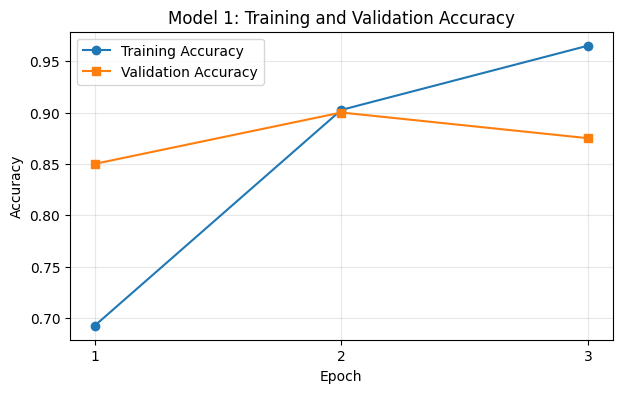

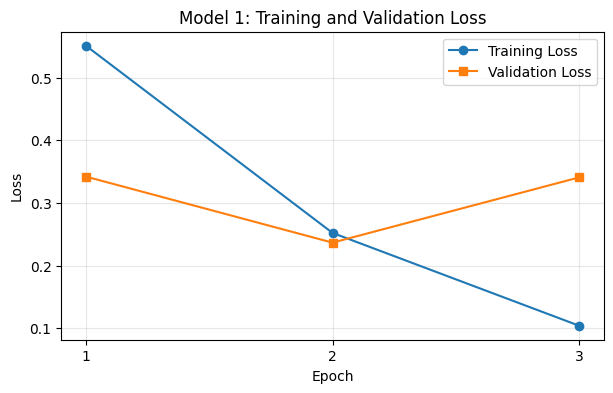

In [37]:
# Model 1 Training and Validation Plots
# No model training is performed.

import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

# Plot training and validation accuracy
plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history1["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history1["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model 1: Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history1["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history1["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 1: Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


##  Model 2: BERT with a ReLU Hidden Layer

###  Model Architecture

Model 2 uses the pretrained `bert-base-uncased` encoder with a classification head containing one hidden layer.

The classification head consists of:
- A linear layer mapping 768 features to 256 hidden neurons.
- A ReLU activation function.
- A final linear layer mapping 256 features to two sentiment classes.

The ReLU activation introduces nonlinearity, allowing the classification head to learn more complex relationships than the linear classifier used in Model 1.

Model 2 is initialized independently from the pretrained BERT checkpoint rather than using the fine-tuned weights of Model 1.

The training dataset, validation dataset, sequence length, learning rate, batch size, and number of epochs remain unchanged to ensure a consistent comparison.


In [38]:
# Model 2 : Initialize BERT with ReLU Classification Head


import torch.nn as nn

# Reset random seeds for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load a fresh pretrained BERT model
# Do not use the fine-tuned Model 1 checkpoint
model2 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2,
    id2label={0: "Negative", 1: "Positive"},
    label2id={"Negative": 0, "Positive": 1}
)

# Replace the default classification head with one hidden layer
model2.classifier = nn.Sequential(
    nn.Linear(768, 256),
    nn.ReLU(),
    nn.Linear(256, 2)
)

# Initialize new linear layers using BERT's initialization
for layer in model2.classifier:
    if isinstance(layer, nn.Linear):
        model2._init_weights(layer)

# Move model to the selected device
model2 = model2.to(device)

# Display the classification head
print("Model 2 Classification Head:")
print(model2.classifier)

# Count parameters
total_params2 = sum(p.numel() for p in model2.parameters())
trainable_params2 = sum(
    p.numel() for p in model2.parameters() if p.requires_grad
)

print(f"\nTotal parameters: {total_params2:,}")
print(f"Trainable parameters: {trainable_params2:,}")

print("\nModel 2 initialized successfully.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1108.88it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Model 2 Classification Head:
Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=2, bias=True)
)

Total parameters: 109,679,618
Trainable parameters: 109,679,618

Model 2 initialized successfully.


### Training Configuration

Model 2 uses the same training configuration as Model 1 to ensure a consistent comparison.

The AdamW optimizer is used with a learning rate of 2e-5 and weight decay of 0.01. The model will be fine-tuned for three epochs with a batch size of 8.

Both the pretrained BERT encoder and the ReLU classification head are trainable.

The best checkpoint will be selected based on validation accuracy, using validation loss to break ties.

In [39]:
# Model 2: Configure AdamW Optimizer

# Create a separate optimizer for Model 2
optimizer2 = AdamW(
    model2.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# Display optimizer settings
print("Model 2 Optimizer: AdamW")
print("Learning rate:", optimizer2.param_groups[0]["lr"])
print("Weight decay:", optimizer2.param_groups[0]["weight_decay"])

# Confirm that the BERT encoder is trainable
print(
    "\nBERT encoder trainable:",
    model2.bert.embeddings.word_embeddings.weight.requires_grad
)

# Confirm that the new hidden layer is trainable
print(
    "Hidden layer trainable:",
    model2.classifier[0].weight.requires_grad
)

# Confirm that the output layer is trainable
print(
    "Output layer trainable:",
    model2.classifier[2].weight.requires_grad
)

print("\nModel 2 optimizer initialized successfully.")

Model 2 Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.01

BERT encoder trainable: True
Hidden layer trainable: True
Output layer trainable: True

Model 2 optimizer initialized successfully.


### Fine-Tuning Model 2

Model 2 is fine-tuned using the same training and validation datasets and hyperparameters as Model 1.

The model uses a classification head with one hidden layer of 256 neurons and ReLU activation.

Training loss, training accuracy, validation loss, and validation accuracy are recorded after each epoch.

The best checkpoint is selected using validation accuracy, with validation loss used to break ties. The selected checkpoint is saved automatically so that the model can be evaluated later without repeating training.

Training time is recorded to compare the computational cost of the different architectures.

In [41]:
# MODEL 2: FINE-TUNING WITH ReLU CLASSIFICATION HEAD

import os
import time

# Create a folder to save Model 2
os.makedirs("saved_models/model2", exist_ok=True)

# Store training and validation results
history2 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Initialize best checkpoint tracking
best_val_accuracy2 = -1.0
best_val_loss2 = float("inf")
best_epoch2 = 0

# Track training time
training_time2 = 0.0
start_time2 = time.perf_counter()

# Train for three epochs using the existing training function
for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}", flush=True)

    # Train Model 2 for one epoch
    train_loss, train_accuracy, epoch_time = train_one_epoch(
        model2, train_loader, optimizer2, device
    )

    training_time2 += epoch_time

    # Evaluate the model on validation data
    val_loss, val_accuracy = evaluate_model(
        model2, val_loader, device
    )

    # Record results
    history2["train_loss"].append(train_loss)
    history2["train_accuracy"].append(train_accuracy)
    history2["val_loss"].append(val_loss)
    history2["val_accuracy"].append(val_accuracy)

    # Check whether this is the best validation checkpoint
    is_best = (
        val_accuracy > best_val_accuracy2
        or (
            val_accuracy == best_val_accuracy2
            and val_loss < best_val_loss2
        )
    )

    if is_best:
        best_val_accuracy2 = val_accuracy
        best_val_loss2 = val_loss
        best_epoch2 = epoch + 1

        # Save complete weights for the custom Model 2 architecture
        torch.save(
            model2.state_dict(),
            "saved_models/model2/best_weights.pt"
        )

        print("Best checkpoint updated and saved.", flush=True)

    # Save training progress after each epoch
    torch.save(
        {
            "history": history2,
            "best_epoch": best_epoch2,
            "best_val_accuracy": best_val_accuracy2,
            "best_val_loss": best_val_loss2,
            "training_time": training_time2
        },
        "saved_models/model2_training_info.pt"
    )

    # Display epoch results
    print(f"Training Loss: {train_loss:.4f}", flush=True)
    print(f"Training Accuracy: {train_accuracy:.4f}", flush=True)
    print(f"Validation Loss: {val_loss:.4f}", flush=True)
    print(f"Validation Accuracy: {val_accuracy:.4f}", flush=True)
    print(f"Epoch Training Time: {epoch_time:.2f} seconds", flush=True)


# Measure total elapsed time
total_time2 = time.perf_counter() - start_time2

# Restore the best checkpoint into the existing Model 2 architecture
best_weights2 = torch.load(
    "saved_models/model2/best_weights.pt",
    map_location="cpu",
    weights_only=True
)

model2.load_state_dict(best_weights2)
model2.to(device)
model2.eval()

# Save the final metrics and timing
torch.save(
    {
        "history": history2,
        "best_epoch": best_epoch2,
        "best_val_accuracy": best_val_accuracy2,
        "best_val_loss": best_val_loss2,
        "training_time": training_time2,
        "total_time": total_time2
    },
    "saved_models/model2_training_info.pt"
)

print("\n" + "=" * 50)
print("MODEL 2 TRAINING COMPLETE")
print("=" * 50)

print("Best epoch:", best_epoch2)
print(f"Best validation accuracy: {best_val_accuracy2:.4f}")
print(f"Best validation loss: {best_val_loss2:.4f}")
print(f"Training time: {training_time2:.2f} seconds")
print(f"Total time: {total_time2:.2f} seconds")
print("Best checkpoint: saved_models/model2/best_weights.pt")



Epoch 1/3
Best checkpoint updated and saved.
Training Loss: 0.5660
Training Accuracy: 0.7212
Validation Loss: 0.3668
Validation Accuracy: 0.8500
Epoch Training Time: 3450.23 seconds

Epoch 2/3
Best checkpoint updated and saved.
Training Loss: 0.3150
Training Accuracy: 0.8862
Validation Loss: 0.2723
Validation Accuracy: 0.8900
Epoch Training Time: 1805.89 seconds

Epoch 3/3
Training Loss: 0.1470
Training Accuracy: 0.9587
Validation Loss: 0.6862
Validation Accuracy: 0.7550
Epoch Training Time: 1806.28 seconds

MODEL 2 TRAINING COMPLETE
Best epoch: 2
Best validation accuracy: 0.8900
Best validation loss: 0.2723
Training time: 7062.40 seconds
Total time: 7427.40 seconds
Best checkpoint: saved_models/model2/best_weights.pt


### Best Model 2: Architecture and Summary

The best checkpoint of Model 2 is selected based on validation accuracy, with validation loss used to break ties.

The model uses the pretrained BERT-base-uncased encoder and a classification head containing one hidden layer with 256 neurons and ReLU activation.

The summary below reports the model architecture, number of trainable parameters, selected epoch, validation performance, and computational cost.

In [42]:
# Model 2: Best Checkpoint Summary

# Switch to evaluation mode
model2.eval()

print("=" * 60)
print("BEST MODEL 2: BERT WITH ReLU HIDDEN LAYER")
print("=" * 60)

# Model architecture
print("\nPretrained model: bert-base-uncased")
print("Model class:", type(model2).__name__)

print("\nBERT Configuration:")
print("Transformer layers:", model2.config.num_hidden_layers)
print("Hidden size:", model2.config.hidden_size)
print("Attention heads:", model2.config.num_attention_heads)
print("Number of classes:", model2.config.num_labels)

# Display classification head
print("\nClassification Head:")
print(model2.classifier)

# Count model parameters
total_params2 = sum(p.numel() for p in model2.parameters())
trainable_params2 = sum(
    p.numel() for p in model2.parameters() if p.requires_grad
)

print("\nModel Parameters:")
print(f"Total parameters: {total_params2:,}")
print(f"Trainable parameters: {trainable_params2:,}")

# Display best checkpoint results
print("\nBest Validation Checkpoint:")
print("Selected epoch:", best_epoch2)
print(f"Validation accuracy: {best_val_accuracy2:.4f}")
print(f"Validation loss: {best_val_loss2:.4f}")
print(f"Training time: {training_time2:.2f} seconds")
print(f"Total time: {total_time2:.2f} seconds")

print("\nModel 2 summary completed.")

BEST MODEL 2: BERT WITH ReLU HIDDEN LAYER

Pretrained model: bert-base-uncased
Model class: BertForSequenceClassification

BERT Configuration:
Transformer layers: 12
Hidden size: 768
Attention heads: 12
Number of classes: 2

Classification Head:
Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=2, bias=True)
)

Model Parameters:
Total parameters: 109,679,618
Trainable parameters: 109,679,618

Best Validation Checkpoint:
Selected epoch: 2
Validation accuracy: 0.8900
Validation loss: 0.2723
Training time: 7062.40 seconds
Total time: 7427.40 seconds

Model 2 summary completed.


### Model 2: Training and Validation Curves

The training and validation accuracy and loss are plotted across the three fine-tuning epochs.

These plots are used to examine model convergence, generalization, and possible overfitting.

The results will also be compared with Model 1 to investigate whether adding a hidden layer with ReLU activation improves classification performance.

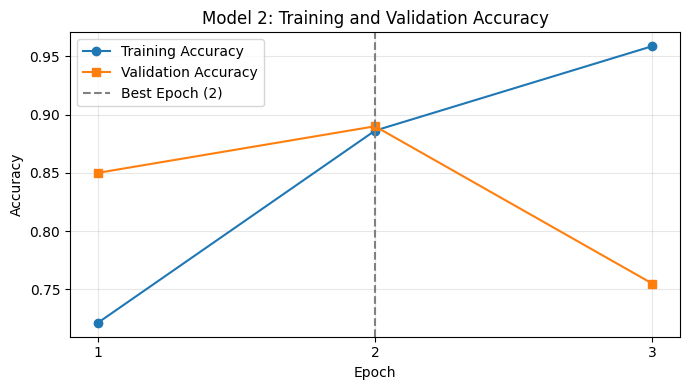

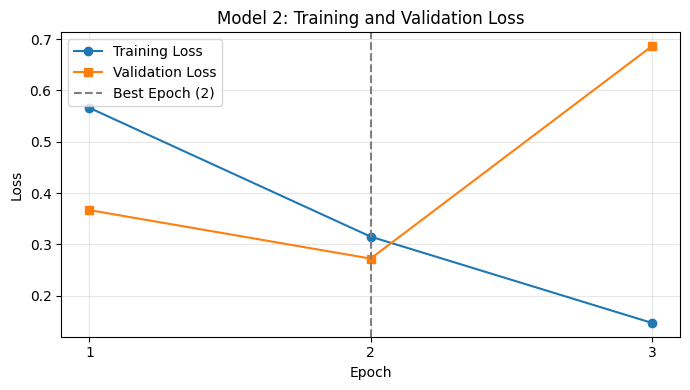

In [43]:
# Model 2: Training and Validation Curves

import matplotlib.pyplot as plt

# Epoch numbers
epochs = range(1, len(history2["train_loss"]) + 1)

# ------------------------------------------------------------
# Plot 1: Training and Validation Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history2["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history2["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

# Mark the best validation epoch
plt.axvline(
    x=best_epoch2,
    linestyle="--",
    color="gray",
    label=f"Best Epoch ({best_epoch2})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model 2: Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: Training and Validation Loss
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history2["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history2["val_loss"],
    marker="s",
    label="Validation Loss"
)

# Mark the best validation epoch
plt.axvline(
    x=best_epoch2,
    linestyle="--",
    color="gray",
    label=f"Best Epoch ({best_epoch2})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 2: Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Model 2: Results and Discussion

Model 2 was designed using the pretrained `bert-base-uncased` encoder with a classification head containing one hidden layer of 256 neurons and ReLU activation.

The model uses the same 800 training and 200 validation reviews as Model 1. It is fine-tuned for three epochs using the same learning rate, batch size, and maximum sequence length.

**Observations**

The training and validation results will be examined to determine whether adding a ReLU hidden layer improves the model's ability to classify positive and negative reviews.

Changes in validation accuracy and validation loss will be used to identify the best checkpoint and assess possible overfitting.

**Best Model Summary**

- Classification head: Linear(768, 256) → ReLU → Linear(256, 2)
- Total trainable parameters: 109,679,618
- Best epoch: TBD
- Best validation accuracy: TBD
- Best validation loss: TBD
- Training time: TBD
- Total training and validation time: TBD

**Comparison with Model 1**

Model 1 achieved a best validation accuracy of 90.00% using a linear classification head without an additional hidden layer.

Model 2 introduces a nonlinear hidden layer, increasing the classification head's capacity. Once training is complete, its validation performance will be compared with Model 1 to determine whether the additional complexity provides a meaningful improvement.

Final test accuracy, confusion matrix, precision, recall, and F1-score will be reported in the final evaluation section after all four models have been trained.

## Model 3: BERT with a GELU Hidden Layer

### Model Architecture

Model 3 uses the pretrained `bert-base-uncased` encoder with a classification head containing one hidden layer of 256 neurons and GELU activation.

The classification head consists of:

- A linear layer mapping 768 input features to 256 hidden neurons.
- A GELU activation function.
- A final linear layer mapping 256 features to two sentiment classes.

GELU is a smooth activation function that scales inputs based on the Gaussian cumulative distribution function, whereas ReLU sets all negative inputs to zero.

Model 3 has the same architecture as Model 2 except for the activation function. All training settings and data splits remain unchanged to allow a direct comparison between ReLU and GELU.

In [44]:
# Model 3: Initialize BERT with GELU Classification Head

# Reset random seeds for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load a fresh pretrained BERT model.
# Do not use the fine-tuned weights from Models 1 or 2.
model3 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2,
    id2label={0: "Negative", 1: "Positive"},
    label2id={"Negative": 0, "Positive": 1}
)

# Replace the default classification head with
# one hidden layer and GELU activation.
model3.classifier = nn.Sequential(
    nn.Linear(768, 256),
    nn.GELU(),
    nn.Linear(256, 2)
)

# Initialize both linear layers using BERT's standard initialization.
for layer in model3.classifier:
    if isinstance(layer, nn.Linear):
        model3._init_weights(layer)

# Move the model to the selected device
model3 = model3.to(device)

# Display the classification head
print("Model 3 Classification Head:")
print(model3.classifier)

# Count total and trainable parameters
total_params3 = sum(p.numel() for p in model3.parameters())
trainable_params3 = sum(
    p.numel() for p in model3.parameters() if p.requires_grad
)

print(f"\nTotal parameters: {total_params3:,}")
print(f"Trainable parameters: {trainable_params3:,}")

print("\nModel 3 initialized successfully.")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 819.98it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

Model 3 Classification Head:
Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): GELU(approximate='none')
  (2): Linear(in_features=256, out_features=2, bias=True)
)

Total parameters: 109,679,618
Trainable parameters: 109,679,618

Model 3 initialized successfully.


### Training Configuration

Model 3 uses the same training configuration as Models 1 and 2.

The AdamW optimizer is initialized with a learning rate of 2e-5 and weight decay of 0.01. The model will be fine-tuned for three epochs with a batch size of 8 and a maximum sequence length of 384 tokens.

All parameters of the pretrained BERT encoder and the GELU classification head remain trainable.

By keeping the dataset, hidden layer size, optimizer, and training settings unchanged, the performance difference between Models 2 and 3 can be examined primarily in terms of their activation functions.


In [45]:
# Model 3: Configure AdamW Optimizer

# Initialize a separate optimizer for Model 3
optimizer3 = AdamW(
    model3.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# Display optimizer settings
print("Model 3 Optimizer: AdamW")
print("Learning rate:", optimizer3.param_groups[0]["lr"])
print("Weight decay:", optimizer3.param_groups[0]["weight_decay"])

# Verify that the pretrained BERT encoder is trainable
print(
    "\nBERT encoder trainable:",
    model3.bert.embeddings.word_embeddings.weight.requires_grad
)

# Verify that both linear layers are trainable
print(
    "Hidden layer trainable:",
    model3.classifier[0].weight.requires_grad
)

print(
    "Output layer trainable:",
    model3.classifier[2].weight.requires_grad
)

print("\nModel 3 optimizer initialized successfully.")

Model 3 Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.01

BERT encoder trainable: True
Hidden layer trainable: True
Output layer trainable: True

Model 3 optimizer initialized successfully.


### Fine-Tuning Model 3

Model 3 is fine-tuned using the same training and validation datasets and hyperparameters as Models 1 and 2.

The classification head consists of one hidden layer with 256 neurons and GELU activation.

Training loss, training accuracy, validation loss, and validation accuracy are recorded for each epoch.

The best checkpoint is selected based on validation accuracy, with validation loss used to break ties. Model weights are saved whenever validation performance improves.

Training time is measured to compare the computational cost of the different classification architectures.


In [46]:
# Model 3: Fine-Tuning with GELU Classification Head

import os
import time

# Create a directory to store Model 3 checkpoints
os.makedirs("saved_models/model3", exist_ok=True)

# Store training and validation metrics
history3 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Track the best validation checkpoint
best_val_accuracy3 = -1.0
best_val_loss3 = float("inf")
best_epoch3 = 0

# Record training time separately from total elapsed time
training_time3 = 0.0
start_time3 = time.perf_counter()

# Fine-tune the model for the specified number of epochs
for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}", flush=True)

    # Train Model 3 for one epoch
    train_loss, train_accuracy, epoch_time = train_one_epoch(
        model3,
        train_loader,
        optimizer3,
        device
    )

    training_time3 += epoch_time

    # Evaluate Model 3 on validation reviews
    val_loss, val_accuracy = evaluate_model(
        model3,
        val_loader,
        device
    )

    # Store training and validation results
    history3["train_loss"].append(train_loss)
    history3["train_accuracy"].append(train_accuracy)
    history3["val_loss"].append(val_loss)
    history3["val_accuracy"].append(val_accuracy)

    # Determine whether this is the best validation checkpoint
    is_best = (
        val_accuracy > best_val_accuracy3
        or (
            val_accuracy == best_val_accuracy3
            and val_loss < best_val_loss3
        )
    )

    if is_best:
        best_val_accuracy3 = val_accuracy
        best_val_loss3 = val_loss
        best_epoch3 = epoch + 1

        # Save the weights of the custom GELU model
        torch.save(
            model3.state_dict(),
            "saved_models/model3/best_weights.pt"
        )

        print("Best checkpoint updated and saved.", flush=True)

    # Save results after every completed epoch
    torch.save(
        {
            "history": history3,
            "best_epoch": best_epoch3,
            "best_val_accuracy": best_val_accuracy3,
            "best_val_loss": best_val_loss3,
            "training_time": training_time3
        },
        "saved_models/model3_training_info.pt"
    )

    # Display epoch results
    print(f"Training Loss: {train_loss:.4f}", flush=True)
    print(f"Training Accuracy: {train_accuracy:.4f}", flush=True)
    print(f"Validation Loss: {val_loss:.4f}", flush=True)
    print(f"Validation Accuracy: {val_accuracy:.4f}", flush=True)
    print(f"Epoch Training Time: {epoch_time:.2f} seconds", flush=True)


# Calculate the total elapsed training and validation time
total_time3 = time.perf_counter() - start_time3

# Restore the best checkpoint in the existing architecture
best_weights3 = torch.load(
    "saved_models/model3/best_weights.pt",
    map_location="cpu",
    weights_only=True
)

model3.load_state_dict(best_weights3)
model3.to(device)
model3.eval()

# Save complete final training information
torch.save(
    {
        "history": history3,
        "best_epoch": best_epoch3,
        "best_val_accuracy": best_val_accuracy3,
        "best_val_loss": best_val_loss3,
        "training_time": training_time3,
        "total_time": total_time3
    },
    "saved_models/model3_training_info.pt"
)

# Display final summary
print("\n" + "=" * 50)
print("MODEL 3 TRAINING COMPLETE")
print("=" * 50)

print("Best epoch:", best_epoch3)
print(f"Best validation accuracy: {best_val_accuracy3:.4f}")
print(f"Best validation loss: {best_val_loss3:.4f}")
print(f"Training time: {training_time3:.2f} seconds")
print(f"Total time: {total_time3:.2f} seconds")
print("Best checkpoint: saved_models/model3/best_weights.pt")


Epoch 1/3
Best checkpoint updated and saved.
Training Loss: 0.6380
Training Accuracy: 0.6238
Validation Loss: 0.3822
Validation Accuracy: 0.8950
Epoch Training Time: 1777.42 seconds

Epoch 2/3
Training Loss: 0.3477
Training Accuracy: 0.8688
Validation Loss: 0.2671
Validation Accuracy: 0.8800
Epoch Training Time: 2516.48 seconds

Epoch 3/3
Training Loss: 0.1467
Training Accuracy: 0.9513
Validation Loss: 0.3979
Validation Accuracy: 0.8350
Epoch Training Time: 3883.73 seconds

MODEL 3 TRAINING COMPLETE
Best epoch: 1
Best validation accuracy: 0.8950
Best validation loss: 0.3822
Training time: 8177.63 seconds
Total time: 8648.72 seconds
Best checkpoint: saved_models/model3/best_weights.pt


### Best Model 3: Architecture and Summary

The best checkpoint of Model 3 is selected using validation accuracy, with validation loss used to break ties.

The model uses the pretrained BERT-base-uncased encoder and a classification head containing one hidden layer with 256 neurons and GELU activation.

The following summary reports the model architecture, trainable parameters, best epoch, validation performance, and computational cost.


In [47]:
# Model 3: Best Checkpoint Summary


# Switch to evaluation mode
model3.eval()

print("=" * 60)
print("BEST MODEL 3: BERT WITH GELU HIDDEN LAYER")
print("=" * 60)

# Display the BERT architecture
print("\nPretrained model: bert-base-uncased")
print("Model class:", type(model3).__name__)

print("\nBERT Configuration:")
print("Transformer layers:", model3.config.num_hidden_layers)
print("Hidden size:", model3.config.hidden_size)
print("Attention heads:", model3.config.num_attention_heads)
print("Number of classes:", model3.config.num_labels)

# Display classification head
print("\nClassification Head:")
print(model3.classifier)

# Count total and trainable parameters
total_params3 = sum(p.numel() for p in model3.parameters())
trainable_params3 = sum(
    p.numel() for p in model3.parameters()
    if p.requires_grad
)

print("\nModel Parameters:")
print(f"Total parameters: {total_params3:,}")
print(f"Trainable parameters: {trainable_params3:,}")

# Display best checkpoint results
print("\nBest Validation Checkpoint:")
print("Selected epoch:", best_epoch3)
print(f"Validation accuracy: {best_val_accuracy3:.4f}")
print(f"Validation loss: {best_val_loss3:.4f}")
print(f"Training time: {training_time3:.2f} seconds")
print(f"Total training and validation time: {total_time3:.2f} seconds")

print("\nModel 3 summary completed.")


BEST MODEL 3: BERT WITH GELU HIDDEN LAYER

Pretrained model: bert-base-uncased
Model class: BertForSequenceClassification

BERT Configuration:
Transformer layers: 12
Hidden size: 768
Attention heads: 12
Number of classes: 2

Classification Head:
Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): GELU(approximate='none')
  (2): Linear(in_features=256, out_features=2, bias=True)
)

Model Parameters:
Total parameters: 109,679,618
Trainable parameters: 109,679,618

Best Validation Checkpoint:
Selected epoch: 1
Validation accuracy: 0.8950
Validation loss: 0.3822
Training time: 8177.63 seconds
Total training and validation time: 8648.72 seconds

Model 3 summary completed.


###  Model 3: Training and Validation Curves

Training and validation accuracy and loss are plotted across the three fine-tuning epochs.

These plots are used to examine convergence, generalization, and potential overfitting.

The best validation epoch is highlighted. The results will be compared with Model 2 to investigate whether replacing ReLU with GELU affects model performance.

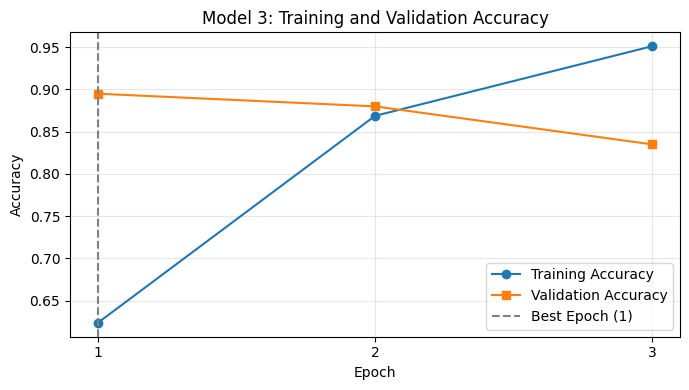

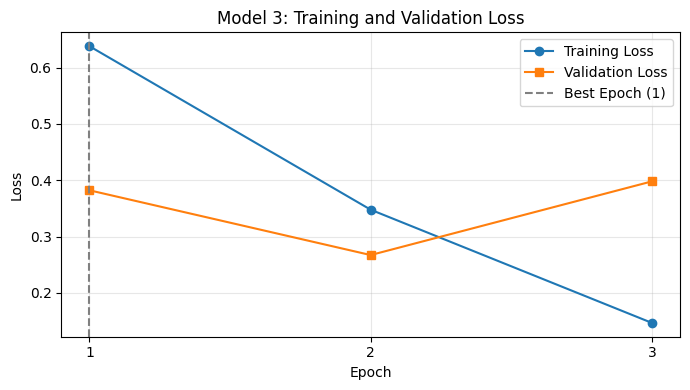

In [48]:
# Model 3: Training and Validation Plots

import matplotlib.pyplot as plt

# Epoch numbers based on recorded training history
epochs = range(1, len(history3["train_loss"]) + 1)

# ------------------------------------------------------------
# Plot 1: Training and Validation Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history3["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history3["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

# Highlight the checkpoint selected using validation performance
plt.axvline(
    best_epoch3,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch3})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model 3: Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: Training and Validation Loss
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history3["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history3["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.axvline(
    best_epoch3,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch3})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 3: Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Model 3: Results and Discussion

Model 3 uses the pretrained `bert-base-uncased` encoder with a classification head containing one hidden layer of 256 neurons and GELU activation.

The model uses the same 800 training and 200 validation reviews as Models 1 and 2. It is fine-tuned for three epochs using the same learning rate, batch size, and maximum sequence length.

**Observations**

The training and validation results will be examined to determine whether the model converges and whether overfitting occurs.

The best checkpoint will be identified based on validation accuracy, with validation loss used to break ties.

**Best Model Summary**

- Classification head: Linear(768, 256) → GELU → Linear(256, 2)
- Total trainable parameters: 109,679,618
- Best epoch: TBD
- Best validation accuracy: TBD
- Best validation loss: TBD
- Training time: TBD
- Total training and validation time: TBD

**Comparison with Model 2**

Models 2 and 3 use identical classification-head dimensions and training settings. The only architectural difference is the activation function.

Model 2 uses ReLU, which sets negative inputs to zero, while Model 3 uses GELU, which smoothly scales its inputs.

Their validation performances will be compared to investigate whether the choice of activation function produces a meaningful difference.

Final test accuracy, confusion matrix, precision, recall, and F1-score will be reported after all four models have been trained.


## 8. Validation-Based Model Selection

The validation performance of Models 1, 2, and 3 is compared to determine which classification-head architecture should be used for Model 4.

The model with the highest validation accuracy is selected. If multiple models achieve the same validation accuracy, the model with the lowest validation loss is preferred.

This selection is performed without using the test dataset to avoid test-data leakage.

Model 4 will retain the selected classification-head architecture but replace its input representation with the average of the [CLS] outputs from the final four BERT transformer blocks.


In [50]:
# Compare Models 1, 2, and 3 on Validation Data

# Collect the best validation results of the first three models
validation_results = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Architecture": [
        "Linear",
        "ReLU Hidden Layer",
        "GELU Hidden Layer"
    ],
    "Best Epoch": [
        best_epoch1,
        best_epoch2,
        best_epoch3
    ],
    "Validation Accuracy": [
        best_val_accuracy1,
        best_val_accuracy2,
        best_val_accuracy3
    ],
    "Validation Loss": [
        best_val_loss1,
        best_val_loss2,
        best_val_loss3
    ]
})

# Rank models by validation accuracy (highest first).
# Use validation loss (lowest first) to break ties.
validation_results = validation_results.sort_values(
    by=["Validation Accuracy", "Validation Loss"],
    ascending=[False, True]
).reset_index(drop=True)

# Display comparison table
print("Validation Performance Comparison:")
display(validation_results)

# Select the best model using validation performance only
best_model_name = validation_results.loc[0, "Model"]

print("\n" + "=" * 50)
print("BEST MODEL SELECTED FOR MODEL 4")
print("=" * 50)
print("Selected model:", best_model_name)
print(
    "Validation accuracy:",
    f"{validation_results.loc[0, 'Validation Accuracy']:.4f}"
)
print(
    "Validation loss:",
    f"{validation_results.loc[0, 'Validation Loss']:.4f}"
)

Validation Performance Comparison:


,Model,Architecture,Best Epoch,Validation Accuracy,Validation Loss
0,Model 1,Linear,2,0.900,0.236544
1,Model 3,GELU Hidden Layer,1,0.895,0.382152
2,Model 2,ReLU Hidden Layer,2,0.890,0.272297



BEST MODEL SELECTED FOR MODEL 4
Selected model: Model 1
Validation accuracy: 0.9000
Validation loss: 0.2365


## Model 4: Averaging the Final Four Transformer Blocks

### Model Architecture

Based on validation performance, Model 1 was selected as the best architecture among the first three models, achieving 90.00% validation accuracy.

Model 4 therefore retains a linear classification head without an additional hidden layer.

Unlike Model 1, Model 4 constructs its classification representation by averaging the [CLS] token outputs from the final four BERT transformer blocks (layers 9–12).

The resulting 768-dimensional representation is passed directly into a linear classification layer with two output logits.

The model is initialized from the original pretrained `bert-base-uncased` checkpoint, rather than from the fine-tuned Model 1 weights.

The same training and validation datasets and hyperparameters will be used. This allows us to investigate whether averaging representations from multiple transformer blocks improves classification performance.


In [51]:
# Model 4: Custom architecture and fresh initialization
# The same custom class is used for both training and subsequent inference.
# Model 4: Average Last Four BERT [CLS] Outputs

import torch.nn as nn
from transformers import BertForSequenceClassification
from transformers.modeling_outputs import SequenceClassifierOutput

# Custom subclass of the required Hugging Face model
class BertLastFourCLS(BertForSequenceClassification):

    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        labels=None,
        **kwargs
    ):

        # Obtain representations from all BERT transformer blocks
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True
        )

        # Select the [CLS] representation from layers 9, 10, 11, 12
        last_four_cls = [
            hidden_state[:, 0, :]
            for hidden_state in outputs.hidden_states[-4:]
        ]

        # Average the four 768-dimensional [CLS] vectors
        averaged_cls = torch.stack(
            last_four_cls, dim=0
        ).mean(dim=0)

        # Apply dropout and the linear classification head
        logits = self.classifier(
            self.dropout(averaged_cls)
        )

        # Calculate cross-entropy loss when labels are provided
        loss = None
        if labels is not None:
            loss = nn.CrossEntropyLoss()(logits, labels)

        return SequenceClassifierOutput(
            loss=loss,
            logits=logits
        )


# Initialize Model 4 independently from pretrained BERT
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model4 = BertLastFourCLS.from_pretrained(
    "bert-base-uncased",
    num_labels=2,
    id2label={0: "Negative", 1: "Positive"},
    label2id={"Negative": 0, "Positive": 1}
)

model4 = model4.to(device)

# Display architecture
print("Model 4 Classification Head:")
print(model4.classifier)

print("\nRepresentation: Average of last 4 [CLS] outputs")

# Count parameters
total_params4 = sum(p.numel() for p in model4.parameters())
trainable_params4 = sum(
    p.numel() for p in model4.parameters()
    if p.requires_grad
)

print(f"\nTotal parameters: {total_params4:,}")
print(f"Trainable parameters: {trainable_params4:,}")

print("\nModel 4 initialized successfully.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1752.44it/s]
[transformers] BertLastFourCLS LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider t

Model 4 Classification Head:
Linear(in_features=768, out_features=2, bias=True)

Representation: Average of last 4 [CLS] outputs

Total parameters: 109,483,778
Trainable parameters: 109,483,778

Model 4 initialized successfully.


###  Training Configuration

Model 4 uses the same training configuration as the first three models to ensure a consistent comparison.

The AdamW optimizer is configured with a learning rate of 2e-5 and weight decay of 0.01. The model will be fine-tuned for three epochs using a batch size of 8 and a maximum sequence length of 384 tokens.

All parameters of the pretrained BERT encoder and the linear classification head remain trainable.

The only architectural change from Model 1 is the representation supplied to the classification head: Model 4 uses the elementwise average of the [CLS] token outputs from the final four transformer blocks.

In [52]:
# Model 4: Configure AdamW Optimizer

# Initialize a separate optimizer for Model 4
optimizer4 = AdamW(
    model4.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# Display optimizer configuration
print("Model 4 Optimizer: AdamW")
print("Learning rate:", optimizer4.param_groups[0]["lr"])
print("Weight decay:", optimizer4.param_groups[0]["weight_decay"])

# Verify that BERT parameters are trainable
print(
    "\nBERT encoder trainable:",
    model4.bert.embeddings.word_embeddings.weight.requires_grad
)

# Verify that the linear classification head is trainable
print(
    "Classification head trainable:",
    model4.classifier.weight.requires_grad
)

print("\nModel 4 optimizer initialized successfully.")

Model 4 Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.01

BERT encoder trainable: True
Classification head trainable: True

Model 4 optimizer initialized successfully.


### Fine-Tuning Model 4

Model 4 is fine-tuned using the same 800 training and 200 validation reviews and the same hyperparameters as Models 1–3.

Instead of using only the final pooled [CLS] representation, the model averages the [CLS] outputs from the final four BERT transformer blocks (layers 9–12). This averaged representation is passed into a linear classification head.

Training loss, training accuracy, validation loss, and validation accuracy are recorded for each epoch.

The best checkpoint is selected using the highest validation accuracy, with the lowest validation loss used to break ties. The best model weights are saved automatically after each improvement.

Training time is measured for comparison with the other models.

In [53]:
# Model 4: Fine-Tuning with Last Four [CLS] Averaging

import os
import time

# Create directory for saving Model 4
os.makedirs("saved_models/model4", exist_ok=True)

# Store training and validation metrics
history4 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Track the best validation checkpoint
best_val_accuracy4 = -1.0
best_val_loss4 = float("inf")
best_epoch4 = 0

# Track computational time
training_time4 = 0.0
start_time4 = time.perf_counter()

# Fine-tune Model 4
for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}", flush=True)

    # Training phase
    train_loss, train_accuracy, epoch_time = train_one_epoch(
        model4,
        train_loader,
        optimizer4,
        device
    )

    training_time4 += epoch_time

    # Validation phase
    val_loss, val_accuracy = evaluate_model(
        model4,
        val_loader,
        device
    )

    # Record epoch metrics
    history4["train_loss"].append(train_loss)
    history4["train_accuracy"].append(train_accuracy)
    history4["val_loss"].append(val_loss)
    history4["val_accuracy"].append(val_accuracy)

    # Determine whether validation performance has improved
    is_best = (
        val_accuracy > best_val_accuracy4
        or (
            val_accuracy == best_val_accuracy4
            and val_loss < best_val_loss4
        )
    )

    if is_best:
        best_val_accuracy4 = val_accuracy
        best_val_loss4 = val_loss
        best_epoch4 = epoch + 1

        # Save weights for the custom Model 4 architecture
        torch.save(
            model4.state_dict(),
            "saved_models/model4/best_weights.pt"
        )

        print("Best checkpoint updated and saved.", flush=True)

    # Save progress after every completed epoch
    torch.save(
        {
            "history": history4,
            "best_epoch": best_epoch4,
            "best_val_accuracy": best_val_accuracy4,
            "best_val_loss": best_val_loss4,
            "training_time": training_time4
        },
        "saved_models/model4_training_info.pt"
    )

    # Display training progress
    print(f"Training Loss: {train_loss:.4f}", flush=True)
    print(f"Training Accuracy: {train_accuracy:.4f}", flush=True)
    print(f"Validation Loss: {val_loss:.4f}", flush=True)
    print(f"Validation Accuracy: {val_accuracy:.4f}", flush=True)
    print(f"Epoch Training Time: {epoch_time:.2f} seconds", flush=True)


# Calculate total training and validation time
total_time4 = time.perf_counter() - start_time4

# Restore the best checkpoint
best_weights4 = torch.load(
    "saved_models/model4/best_weights.pt",
    map_location="cpu",
    weights_only=True
)

model4.load_state_dict(best_weights4)
model4.to(device)
model4.eval()

# Save final metrics and timing
torch.save(
    {
        "history": history4,
        "best_epoch": best_epoch4,
        "best_val_accuracy": best_val_accuracy4,
        "best_val_loss": best_val_loss4,
        "training_time": training_time4,
        "total_time": total_time4
    },
    "saved_models/model4_training_info.pt"
)

# Display final results
print("\n" + "=" * 50)
print("MODEL 4 TRAINING COMPLETE")
print("=" * 50)

print("Best epoch:", best_epoch4)
print(f"Best validation accuracy: {best_val_accuracy4:.4f}")
print(f"Best validation loss: {best_val_loss4:.4f}")
print(f"Training time: {training_time4:.2f} seconds")
print(f"Total time: {total_time4:.2f} seconds")
print("Best checkpoint: saved_models/model4/best_weights.pt")


Epoch 1/3
Best checkpoint updated and saved.
Training Loss: 0.4804
Training Accuracy: 0.7550
Validation Loss: 0.3195
Validation Accuracy: 0.8650
Epoch Training Time: 2135.41 seconds

Epoch 2/3
Best checkpoint updated and saved.
Training Loss: 0.1777
Training Accuracy: 0.9337
Validation Loss: 0.3060
Validation Accuracy: 0.8800
Epoch Training Time: 1991.18 seconds

Epoch 3/3
Best checkpoint updated and saved.
Training Loss: 0.0646
Training Accuracy: 0.9812
Validation Loss: 0.2932
Validation Accuracy: 0.9150
Epoch Training Time: 2014.36 seconds

MODEL 4 TRAINING COMPLETE
Best epoch: 3
Best validation accuracy: 0.9150
Best validation loss: 0.2932
Training time: 6140.95 seconds
Total time: 6483.19 seconds
Best checkpoint: saved_models/model4/best_weights.pt


### Best Model 4: Architecture and Summary

The best checkpoint of Model 4 is selected using validation accuracy, with validation loss used to break ties.

Model 4 retains the linear classification head from Model 1, which achieved the highest validation accuracy among Models 1–3.

However, instead of using the final pooled [CLS] representation, Model 4 averages the [CLS] token outputs from the last four BERT transformer blocks.

The following summary reports the model architecture, total and trainable parameters, best epoch, validation performance, and computational cost.

In [54]:
# Model 4: Best Checkpoint Summary

# Switch the selected checkpoint to evaluation mode
model4.eval()

print("=" * 60)
print("BEST MODEL 4: AVERAGE OF LAST FOUR BERT [CLS] OUTPUTS")
print("=" * 60)

# Display model information
print("\nPretrained model: bert-base-uncased")
print("Model class:", type(model4).__name__)

print("\nBERT Configuration:")
print("Transformer layers:", model4.config.num_hidden_layers)
print("Hidden size:", model4.config.hidden_size)
print("Attention heads:", model4.config.num_attention_heads)
print("Number of classes:", model4.config.num_labels)

# Describe the representation used for classification
print("\nClassification Representation:")
print("Average of [CLS] outputs from transformer layers 9–12")

# Display the linear classification head
print("\nClassification Head:")
print(model4.classifier)

# Count total and trainable parameters
total_params4 = sum(p.numel() for p in model4.parameters())

trainable_params4 = sum(
    p.numel() for p in model4.parameters()
    if p.requires_grad
)

print("\nModel Parameters:")
print(f"Total parameters: {total_params4:,}")
print(f"Trainable parameters: {trainable_params4:,}")

# Display selected checkpoint results
print("\nBest Validation Checkpoint:")
print("Selected epoch:", best_epoch4)
print(f"Validation accuracy: {best_val_accuracy4:.4f}")
print(f"Validation loss: {best_val_loss4:.4f}")
print(f"Training time: {training_time4:.2f} seconds")
print(f"Total training and validation time: {total_time4:.2f} seconds")

print("\nModel 4 summary completed.")


BEST MODEL 4: AVERAGE OF LAST FOUR BERT [CLS] OUTPUTS

Pretrained model: bert-base-uncased
Model class: BertLastFourCLS

BERT Configuration:
Transformer layers: 12
Hidden size: 768
Attention heads: 12
Number of classes: 2

Classification Representation:
Average of [CLS] outputs from transformer layers 9–12

Classification Head:
Linear(in_features=768, out_features=2, bias=True)

Model Parameters:
Total parameters: 109,483,778
Trainable parameters: 109,483,778

Best Validation Checkpoint:
Selected epoch: 3
Validation accuracy: 0.9150
Validation loss: 0.2932
Training time: 6140.95 seconds
Total training and validation time: 6483.19 seconds

Model 4 summary completed.


### Model 4: Training and Validation Curves

Training and validation accuracy and loss are plotted across the three fine-tuning epochs.

These plots are used to examine model convergence, generalization, and possible overfitting.

The checkpoint selected using validation performance is highlighted in both plots.

The results will be compared with Model 1 to investigate whether averaging the [CLS] representations from the final four transformer blocks improves classification performance.


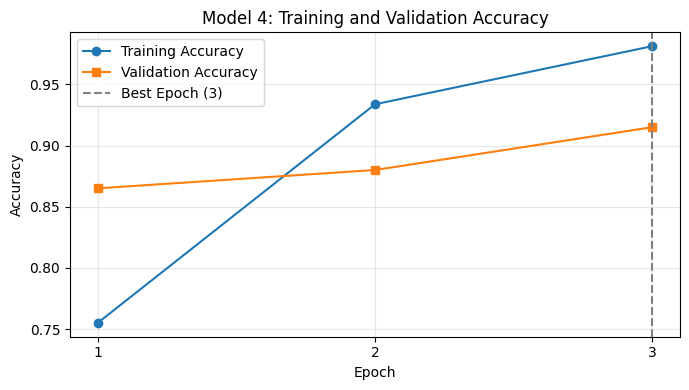

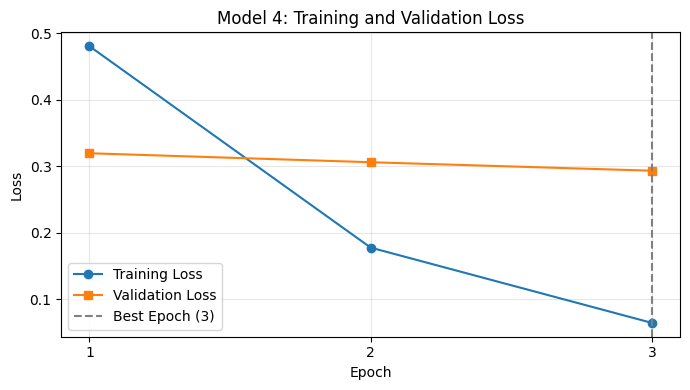

In [55]:
# Model 4: Training and Validation Curves


import matplotlib.pyplot as plt

# Epoch numbers based on completed training history
epochs = range(1, len(history4["train_loss"]) + 1)

# ------------------------------------------------------------
# Plot 1: Training and Validation Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history4["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history4["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

# Highlight the best validation checkpoint
plt.axvline(
    x=best_epoch4,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch4})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model 4: Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: Training and Validation Loss
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    epochs,
    history4["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history4["val_loss"],
    marker="s",
    label="Validation Loss"
)

# Highlight the best validation checkpoint
plt.axvline(
    x=best_epoch4,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch4})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 4: Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### 9.6 Model 4: Results and Discussion

Model 4 uses the pretrained `bert-base-uncased` encoder with a linear classification head and an averaged representation of the [CLS] token outputs from the final four transformer blocks.

The model was fine-tuned using 800 training reviews and evaluated using 200 validation reviews over three epochs.

**Training and Validation Results**

| Epoch | Training Loss | Training Accuracy | Validation Loss | Validation Accuracy |
|---|---:|---:|---:|---:|
| 1 | 0.4804 | 75.50% | 0.3195 | 86.50% |
| 2 | 0.1777 | 93.37% | 0.3060 | 88.00% |
| 3 | 0.0646 | 98.12% | 0.2932 | 91.50% |

**Observations**

Training accuracy increased throughout the three epochs, reaching 98.12% in Epoch 3. Validation accuracy also improved consistently, increasing from 86.50% to 91.50%.

Validation loss decreased from 0.3195 to 0.2932, indicating improved validation performance across the training epochs.

Although the difference between training and validation accuracy suggests some overfitting, Model 4 achieved its best validation performance during the final epoch.

**Best Model Summary**

- Classification head: Linear(768, 2)
- Input representation: Average of [CLS] outputs from transformer blocks 9–12
- Total trainable parameters: 109,483,778
- Best epoch: 3
- Best validation accuracy: 91.50%
- Best validation loss: 0.2932
- Training time: 6140.95 seconds
- Total training and validation time: 6483.19 seconds

**Comparison with Model 1**

Model 1 achieved 90.00% validation accuracy using the standard pooled [CLS] representation.

Model 4 achieved 91.50% validation accuracy using the average of the final four transformer-block [CLS] representations.

This corresponds to an improvement of 1.5 percentage points, or three additional correctly classified validation reviews.

The improvement suggests that combining representations from multiple transformer blocks may provide useful information for sentiment classification. However, the difference is small, and test-set evaluation is necessary to determine whether the advantage generalizes.

Final test accuracy, confusion matrix, precision, recall, F1-score, and inference time will be reported in the next section.


## Final Test Evaluation

### Test Prediction and Inference Time

The four fine-tuned BERT models are evaluated using the original 400 test reviews from Homework 1.

The test dataset contains 200 negative and 200 positive reviews and was not used during training, validation, or model selection.

Each model is evaluated using its best checkpoint selected on validation data.

During testing, model parameters are not updated. Predicted sentiment labels and true labels are collected for calculating confusion matrices, per-class precision, recall, F1-score, and overall accuracy.

Inference time is measured to compare the computational cost of the BERT classifiers with the Naïve Bayes classifier from Homework 1.


In [56]:
# Define Test Prediction and Inference Function


import time
import numpy as np
import torch

def predict_on_test(model, data_loader, device):

    # Disable dropout and enable evaluation behavior
    model.eval()

    all_predictions = []
    all_labels = []

    # Synchronize before timing when using a CUDA GPU
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # Disable gradient calculations during inference
    with torch.inference_mode():

        for batch in data_loader:

            # Move inputs to the selected device
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            # Run the model without providing labels
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Select the class with the highest logit
            predictions = torch.argmax(
                outputs.logits, dim=1
            )

            # Collect predictions and true labels
            all_predictions.extend(
                predictions.cpu().tolist()
            )
            all_labels.extend(
                labels.cpu().tolist()
            )

    # Ensure GPU operations finish before stopping the timer
    if device.type == "cuda":
        torch.cuda.synchronize()

    inference_time = time.perf_counter() - start_time

    return (
        np.array(all_labels),
        np.array(all_predictions),
        inference_time
    )


print("Test prediction function defined successfully.")


Test prediction function defined successfully.


### Test Predictions: Model 1

The best checkpoint of Model 1, selected at Epoch 2 using validation accuracy, is evaluated on the original 400 test reviews.

Predicted sentiment labels are collected and compared with the true labels. The total inference time and average inference time per review are recorded.

The model is evaluated without updating its parameters. These predictions will be used to calculate the confusion matrix, precision, recall, F1-score, and accuracy.


In [57]:
# Evaluate Best Model 1 on the Test Dataset

# Model 1 already contains its best checkpoint from Epoch 2.
# This cell performs inference only; it does not update weights.

y_true1, y_pred1, inference_time1 = predict_on_test(
    model1,
    test_loader,
    device
)

# Verify that all 400 reviews were evaluated
print("Number of test reviews:", len(y_true1))
print("Number of predictions:", len(y_pred1))

# Check the distribution of predicted labels
print("\nPredicted sentiment distribution:")
print("Negative:", np.sum(y_pred1 == 0))
print("Positive:", np.sum(y_pred1 == 1))

# Display inference timing
print(f"\nTotal inference time: {inference_time1:.2f} seconds")
print(
    f"Average inference time per review: "
    f"{inference_time1 / len(y_true1):.4f} seconds"
)

# Verify that the predicted labels are valid
assert len(y_pred1) == 400
assert set(np.unique(y_pred1)).issubset({0, 1})

print("\nModel 1 test predictions completed successfully.")

Number of test reviews: 400
Number of predictions: 400

Predicted sentiment distribution:
Negative: 197
Positive: 203

Total inference time: 268.73 seconds
Average inference time per review: 0.6718 seconds

Model 1 test predictions completed successfully.


###  Model 1: Confusion Matrix and Classification Report

The predictions generated by the best Model 1 checkpoint are compared with the true sentiment labels for the 400 test reviews.

The following evaluation metrics are calculated:

- Confusion matrix
- Precision for negative and positive reviews
- Recall for negative and positive reviews
- F1-score for each class
- Overall test accuracy

The confusion matrix shows the number of correct and incorrect predictions for both sentiment classes.

The classification report provides a detailed evaluation of Model 1's performance on the previously unseen test dataset.


MODEL 1: FINAL TEST EVALUATION

Test Accuracy: 0.8725

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8782    0.8650    0.8715       200
    Positive     0.8670    0.8800    0.8734       200

    accuracy                         0.8725       400
   macro avg     0.8726    0.8725    0.8725       400
weighted avg     0.8726    0.8725    0.8725       400


Confusion Matrix:
[[173  27]
 [ 24 176]]

Total Inference Time: 268.73 seconds
Average Time per Review: 0.6718 seconds


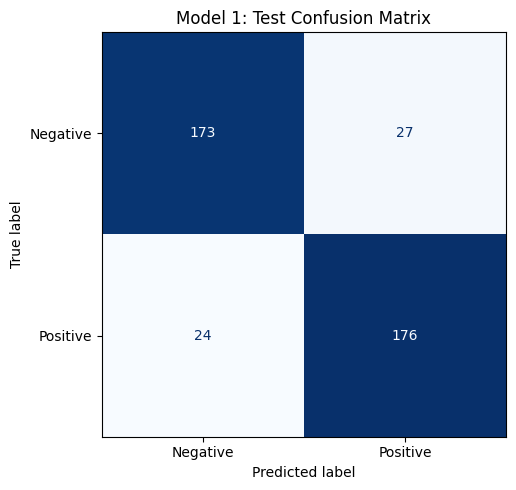


Model 1 test evaluation completed.


In [58]:
# Model 1 - Test Classification Metrics

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Calculate overall test accuracy
test_accuracy1 = accuracy_score(y_true1, y_pred1)

# Generate classification report
report1 = classification_report(
    y_true1,
    y_pred1,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

# Calculate confusion matrix
cm1 = confusion_matrix(
    y_true1,
    y_pred1,
    labels=[0, 1]
)

# Display results
print("=" * 60)
print("MODEL 1: FINAL TEST EVALUATION")
print("=" * 60)

print(f"\nTest Accuracy: {test_accuracy1:.4f}")

print("\nClassification Report:")
print(report1)

print("\nConfusion Matrix:")
print(cm1)

print(f"\nTotal Inference Time: {inference_time1:.2f} seconds")
print(
    f"Average Time per Review: "
    f"{inference_time1 / len(y_true1):.4f} seconds"
)

# Plot confusion matrix
disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm1,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp1.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Model 1: Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nModel 1 test evaluation completed.")


### Model 2: Test Predictions and Inference Time

Model 2 uses a pretrained BERT encoder followed by a classification head containing a 256-neuron hidden layer with ReLU activation.

The best checkpoint, selected at Epoch 2, is evaluated using the same 400 test reviews used for Model 1.

The predicted labels, true labels, and inference time are recorded. This ensures that Model 2 can be compared directly with the other BERT architectures using identical test data.

No model parameters are updated during evaluation.


In [59]:
# Evaluate Best Model 2 on the Test Dataset

# Model 2's best checkpoint was restored after training.
# This cell performs inference only.

y_true2, y_pred2, inference_time2 = predict_on_test(
    model2,
    test_loader,
    device
)

# Verify number of evaluated reviews
print("Number of test reviews:", len(y_true2))
print("Number of predictions:", len(y_pred2))

# Verify that the test labels match Model 1
assert np.array_equal(y_true1, y_true2), (
    "Model 1 and Model 2 test labels do not match."
)

# Display predicted sentiment distribution
print("\nPredicted sentiment distribution:")
print("Negative:", np.sum(y_pred2 == 0))
print("Positive:", np.sum(y_pred2 == 1))

# Calculate inference timing
print(f"\nTotal inference time: {inference_time2:.2f} seconds")
print(
    f"Average inference time per review: "
    f"{inference_time2 / len(y_true2):.4f} seconds"
)

# Verify output validity
assert len(y_pred2) == 400
assert set(np.unique(y_pred2)).issubset({0, 1})

print("\nModel 2 test predictions completed successfully.")

Number of test reviews: 400
Number of predictions: 400

Predicted sentiment distribution:
Negative: 195
Positive: 205

Total inference time: 218.58 seconds
Average inference time per review: 0.5465 seconds

Model 2 test predictions completed successfully.


### Model 2: Confusion Matrix and Classification Report

The best Model 2 checkpoint, consisting of a pretrained BERT encoder and a ReLU-based classification head, is evaluated on the original 400 test reviews.

The predicted sentiment labels are compared against the true labels to calculate overall accuracy and per-class precision, recall, and F1-score.

A confusion matrix is also generated to show the number of correctly and incorrectly classified negative and positive reviews.

Inference time is reported to compare the computational cost of Model 2 with the other BERT models.

MODEL 2: FINAL TEST EVALUATION

Test Accuracy: 0.8875

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8974    0.8750    0.8861       200
    Positive     0.8780    0.9000    0.8889       200

    accuracy                         0.8875       400
   macro avg     0.8877    0.8875    0.8875       400
weighted avg     0.8877    0.8875    0.8875       400


Confusion Matrix:
[[175  25]
 [ 20 180]]

Total Inference Time: 218.58 seconds
Average Time per Review: 0.5465 seconds


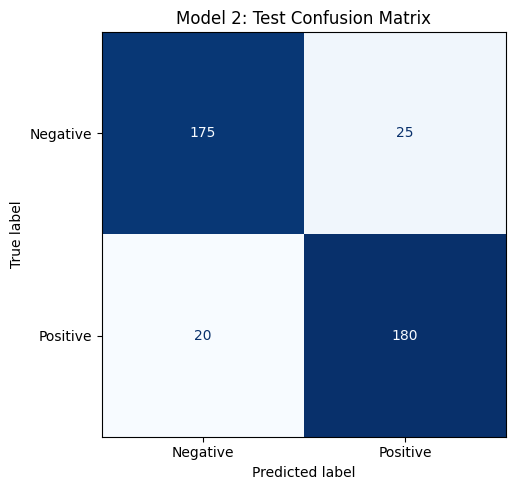


Model 2 test evaluation completed.


In [60]:
# Model 2 - Test Classification Metrics

# Calculate overall test accuracy
test_accuracy2 = accuracy_score(y_true2, y_pred2)

# Generate per-class classification report
report2 = classification_report(
    y_true2,
    y_pred2,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

# Calculate confusion matrix
cm2 = confusion_matrix(
    y_true2,
    y_pred2,
    labels=[0, 1]
)

# Display results
print("=" * 60)
print("MODEL 2: FINAL TEST EVALUATION")
print("=" * 60)

print(f"\nTest Accuracy: {test_accuracy2:.4f}")

print("\nClassification Report:")
print(report2)

print("\nConfusion Matrix:")
print(cm2)

print(f"\nTotal Inference Time: {inference_time2:.2f} seconds")
print(
    f"Average Time per Review: "
    f"{inference_time2 / len(y_true2):.4f} seconds"
)

# Plot confusion matrix
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm2,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp2.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Model 2: Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nModel 2 test evaluation completed.")


### Model 3: Test Predictions and Inference Time

Model 3 uses the pretrained `bert-base-uncased` encoder with a classification head consisting of a 256-neuron hidden layer and GELU activation.

The best checkpoint, selected at Epoch 1 based on validation accuracy, is evaluated on the original 400 test reviews.

Predicted sentiment labels and true labels are collected to calculate classification metrics.

Total inference time and average inference time per review are measured for comparison with the other BERT models.

No additional training or parameter updates are performed.

In [61]:
# Evaluate Best Model 3 on the Test Dataset

# Model 3 contains the best checkpoint from Epoch 1.
# Perform inference on the same 400 test reviews.

y_true3, y_pred3, inference_time3 = predict_on_test(
    model3,
    test_loader,
    device
)

# Verify the number of evaluated reviews
print("Number of test reviews:", len(y_true3))
print("Number of predictions:", len(y_pred3))

# Confirm identical test labels across models
assert np.array_equal(y_true1, y_true3), (
    "Model 1 and Model 3 test labels do not match."
)

assert np.array_equal(y_true2, y_true3), (
    "Model 2 and Model 3 test labels do not match."
)

# Display predicted sentiment distribution
print("\nPredicted sentiment distribution:")
print("Negative:", np.sum(y_pred3 == 0))
print("Positive:", np.sum(y_pred3 == 1))

# Display inference timing
print(f"\nTotal inference time: {inference_time3:.2f} seconds")
print(
    f"Average inference time per review: "
    f"{inference_time3 / len(y_true3):.4f} seconds"
)

# Verify output validity
assert len(y_pred3) == 400
assert set(np.unique(y_pred3)).issubset({0, 1})

print("\nModel 3 test predictions completed successfully.")


Number of test reviews: 400
Number of predictions: 400

Predicted sentiment distribution:
Negative: 199
Positive: 201

Total inference time: 224.56 seconds
Average inference time per review: 0.5614 seconds

Model 3 test predictions completed successfully.


### Model 3: Confusion Matrix and Classification Report

The best Model 3 checkpoint, consisting of a pretrained BERT encoder and a GELU-based classification head, is evaluated using the original 400 test reviews.

The predicted sentiment labels are compared against the true labels to calculate overall accuracy and per-class precision, recall, and F1-score.

A confusion matrix is generated to examine correct and incorrect classifications for negative and positive reviews.

Inference time is also reported for comparison with the other BERT architectures.


MODEL 3: FINAL TEST EVALUATION

Test Accuracy: 0.8625

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8643    0.8600    0.8622       200
    Positive     0.8607    0.8650    0.8628       200

    accuracy                         0.8625       400
   macro avg     0.8625    0.8625    0.8625       400
weighted avg     0.8625    0.8625    0.8625       400


Confusion Matrix:
[[172  28]
 [ 27 173]]

Total Inference Time: 224.56 seconds
Average Time per Review: 0.5614 seconds


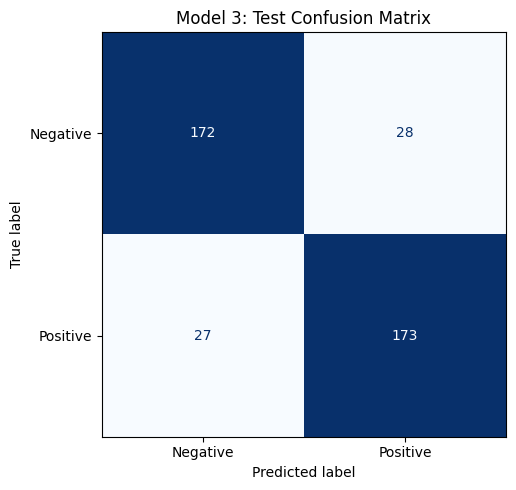


Model 3 test evaluation completed.


In [62]:
# Cell Model 3 - Test Classification Metrics
# No training or additional inference is performed.


# Calculate overall test accuracy
test_accuracy3 = accuracy_score(y_true3, y_pred3)

# Generate per-class classification report
report3 = classification_report(
    y_true3,
    y_pred3,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

# Calculate confusion matrix
cm3 = confusion_matrix(
    y_true3,
    y_pred3,
    labels=[0, 1]
)

# Display results
print("=" * 60)
print("MODEL 3: FINAL TEST EVALUATION")
print("=" * 60)

print(f"\nTest Accuracy: {test_accuracy3:.4f}")

print("\nClassification Report:")
print(report3)

print("\nConfusion Matrix:")
print(cm3)

print(f"\nTotal Inference Time: {inference_time3:.2f} seconds")
print(
    f"Average Time per Review: "
    f"{inference_time3 / len(y_true3):.4f} seconds"
)

# Plot confusion matrix
disp3 = ConfusionMatrixDisplay(
    confusion_matrix=cm3,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp3.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Model 3: Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nModel 3 test evaluation completed.")


### Model 4: Test Predictions and Inference Time

Model 4 uses the pretrained `bert-base-uncased` encoder with a linear classification head.

Unlike Model 1, which uses the standard pooled [CLS] representation, Model 4 averages the [CLS] token outputs from the final four transformer blocks (layers 9–12).

The best checkpoint, selected at Epoch 3 with a validation accuracy of 91.50%, is evaluated on the original 400 test reviews.

Predicted sentiment labels and inference time are recorded for comparison with Models 1–3.

No parameters are updated during evaluation.

In [63]:
# Evaluate Best Model 4 on the Test Dataset
# No additional training is performed.
# ============================================================

# Model 4 contains the best checkpoint from Epoch 3.
# Evaluate using the same test dataset as Models 1, 2 and 3.

y_true4, y_pred4, inference_time4 = predict_on_test(
    model4,
    test_loader,
    device
)

# Verify the number of test reviews
print("Number of test reviews:", len(y_true4))
print("Number of predictions:", len(y_pred4))

# Verify that test labels are identical across all models
assert np.array_equal(y_true1, y_true4), (
    "Model 1 and Model 4 test labels do not match."
)

assert np.array_equal(y_true2, y_true4), (
    "Model 2 and Model 4 test labels do not match."
)

assert np.array_equal(y_true3, y_true4), (
    "Model 3 and Model 4 test labels do not match."
)

# Display predicted sentiment distribution
print("\nPredicted sentiment distribution:")
print("Negative:", np.sum(y_pred4 == 0))
print("Positive:", np.sum(y_pred4 == 1))

# Display inference timing
print(f"\nTotal inference time: {inference_time4:.2f} seconds")
print(
    f"Average inference time per review: "
    f"{inference_time4 / len(y_true4):.4f} seconds"
)

# Verify prediction validity
assert len(y_pred4) == 400
assert set(np.unique(y_pred4)).issubset({0, 1})

print("\nModel 4 test predictions completed successfully.")

Number of test reviews: 400
Number of predictions: 400

Predicted sentiment distribution:
Negative: 216
Positive: 184

Total inference time: 229.93 seconds
Average inference time per review: 0.5748 seconds

Model 4 test predictions completed successfully.


### Model 4: Confusion Matrix and Classification Report

The best Model 4 checkpoint, selected at Epoch 3, is evaluated on the original 400 test reviews.

The model averages the [CLS] token outputs from the final four BERT transformer blocks and passes the resulting representation through a linear classification head.

The predicted sentiment labels are compared with the true labels to calculate overall test accuracy and per-class precision, recall, and F1-score.

A confusion matrix is generated to examine correct and incorrect predictions for negative and positive reviews.

Inference time is also reported to compare the computational efficiency of Model 4 with the other BERT architectures.

These results will be used in the final comparison of all four models.


MODEL 4: FINAL TEST EVALUATION

Test Accuracy: 0.8600

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8333    0.9000    0.8654       200
    Positive     0.8913    0.8200    0.8542       200

    accuracy                         0.8600       400
   macro avg     0.8623    0.8600    0.8598       400
weighted avg     0.8623    0.8600    0.8598       400


Confusion Matrix:
[[180  20]
 [ 36 164]]

Total Inference Time: 229.93 seconds
Average Time per Review: 0.5748 seconds


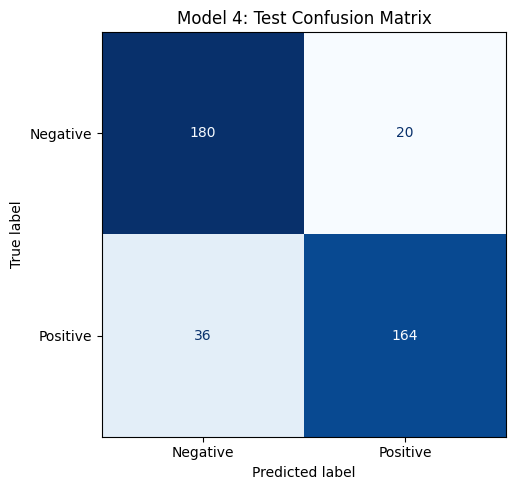


Model 4 test evaluation completed.


In [64]:
# Model 4 - Test Classification Metrics
# No training or additional inference is performed.


# Calculate overall test accuracy
test_accuracy4 = accuracy_score(y_true4, y_pred4)

# Generate per-class classification report
report4 = classification_report(
    y_true4,
    y_pred4,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

# Calculate confusion matrix
cm4 = confusion_matrix(
    y_true4,
    y_pred4,
    labels=[0, 1]
)

# Display results
print("=" * 60)
print("MODEL 4: FINAL TEST EVALUATION")
print("=" * 60)

print(f"\nTest Accuracy: {test_accuracy4:.4f}")

print("\nClassification Report:")
print(report4)

print("\nConfusion Matrix:")
print(cm4)

print(f"\nTotal Inference Time: {inference_time4:.2f} seconds")
print(
    f"Average Time per Review: "
    f"{inference_time4 / len(y_true4):.4f} seconds"
)

# Plot confusion matrix
disp4 = ConfusionMatrixDisplay(
    confusion_matrix=cm4,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp4.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Model 4: Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nModel 4 test evaluation completed.")


### Final Comparison of BERT Models

The four fine-tuned BERT models are compared using the same 400 previously unseen test reviews.

The following metrics are reported for each model:

- Test accuracy
- Macro-averaged precision, recall, and F1-score
- Best validation accuracy
- Total training and validation time
- Total inference time
- Average inference time per review

Macro-averaged metrics assign equal importance to negative and positive sentiment classes.

Model 4 achieved the highest validation accuracy (91.50%) and was therefore selected as the best model before examining the test results.

The test results are presented to assess how well the models generalize to unseen reviews.

Differences in computational cost are also examined to compare the efficiency of the four architectures.


In [65]:
# Final Comparison of All Four BERT Models
# No training or inference is performed.

import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# Collect the saved results from all four models
model_results = [
    {
        "Model": "Model 1",
        "Architecture": "Linear",
        "y_true": y_true1,
        "y_pred": y_pred1,
        "val_accuracy": best_val_accuracy1,
        "training_time": total_time1,
        "inference_time": inference_time1
    },
    {
        "Model": "Model 2",
        "Architecture": "ReLU Hidden Layer",
        "y_true": y_true2,
        "y_pred": y_pred2,
        "val_accuracy": best_val_accuracy2,
        "training_time": total_time2,
        "inference_time": inference_time2
    },
    {
        "Model": "Model 3",
        "Architecture": "GELU Hidden Layer",
        "y_true": y_true3,
        "y_pred": y_pred3,
        "val_accuracy": best_val_accuracy3,
        "training_time": total_time3,
        "inference_time": inference_time3
    },
    {
        "Model": "Model 4",
        "Architecture": "Last 4 CLS Average",
        "y_true": y_true4,
        "y_pred": y_pred4,
        "val_accuracy": best_val_accuracy4,
        "training_time": total_time4,
        "inference_time": inference_time4
    }
]

comparison_rows = []

for result in model_results:

    # Calculate macro-averaged precision, recall and F1
    precision, recall, f1, _ = precision_recall_fscore_support(
        result["y_true"],
        result["y_pred"],
        labels=[0, 1],
        average="macro",
        zero_division=0
    )

    # Calculate test accuracy
    accuracy = accuracy_score(
        result["y_true"],
        result["y_pred"]
    )

    comparison_rows.append({
        "Model": result["Model"],
        "Architecture": result["Architecture"],
        "Validation Accuracy": result["val_accuracy"],
        "Test Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training + Val Time (min)": result["training_time"] / 60,
        "Inference Time (s)": result["inference_time"],
        "Time per Review (s)": (
            result["inference_time"] / len(result["y_true"])
        )
    })

# Create the comparison DataFrame
comparison_df = pd.DataFrame(comparison_rows)

# Display all four models
print("=" * 65)
print("FINAL COMPARISON OF ALL FOUR BERT MODELS")
print("=" * 65)

display(comparison_df.round(4))

# Select the best model using validation accuracy,
# not by selecting the highest test accuracy
best_model_row = comparison_df.loc[
    comparison_df["Validation Accuracy"].idxmax()
]

print("\nBest Model Selected Using Validation Accuracy:")
print("Model:", best_model_row["Model"])
print("Architecture:", best_model_row["Architecture"])
print(
    f"Validation Accuracy: "
    f"{best_model_row['Validation Accuracy']:.4f}"
)
print(
    f"Test Accuracy: "
    f"{best_model_row['Test Accuracy']:.4f}"
)
print(
    f"Macro F1: "
    f"{best_model_row['Macro F1']:.4f}"
)

print("\nFinal model comparison completed.")


FINAL COMPARISON OF ALL FOUR BERT MODELS


,Model,Architecture,Validation Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Val Time (min),Inference Time (s),Time per Review (s)
0,Model 1,Linear,0.900,0.8725,0.8726,0.8725,0.8725,98.5818,268.7337,0.6718
1,Model 2,ReLU Hidden Layer,0.890,0.8875,0.8877,0.8875,0.8875,123.7900,218.5808,0.5465
2,Model 3,GELU Hidden Layer,0.895,0.8625,0.8625,0.8625,0.8625,144.1454,224.5602,0.5614
3,Model 4,Last 4 CLS Average,0.915,0.8600,0.8623,0.8600,0.8598,108.0531,229.9344,0.5748



Best Model Selected Using Validation Accuracy:
Model: Model 4
Architecture: Last 4 CLS Average
Validation Accuracy: 0.9150
Test Accuracy: 0.8600
Macro F1: 0.8598

Final model comparison completed.


### Discussion of Final BERT Results

All four BERT architectures were evaluated using the same 400 held-out IMDb movie reviews.

Model 2, which used a 256-neuron ReLU classification head, achieved the highest test accuracy of 88.75% and macro F1-score of 0.8875.

Model 1 achieved 87.25% test accuracy, while Model 3 achieved 86.25%.

Model 4 achieved the highest validation accuracy of 91.50%, but its test accuracy was 86.00%. This indicates that its advantage on validation data did not translate into better performance on the held-out test set.

The 5.5 percentage-point difference between Model 4's validation and test accuracy suggests that its performance estimate was sensitive to the evaluation sample. The relatively small dataset sizes may contribute to this variation.

Model 4 was selected before test evaluation based on its validation performance. Therefore, it remains the validation-selected model, while Model 2 is reported separately as the model with the highest observed test accuracy.

These findings suggest that using a more complex classification head or averaging representations from multiple BERT layers does not necessarily improve generalization.

All four models required substantial fine-tuning time on CPU hardware. Differences in measured inference time should be interpreted cautiously because timing can vary with system conditions.

The next section compares the BERT results against the Naïve Bayes baseline from Homework 1.

## Comparison with Assignment 1: Naïve Bayes

### Classification Performance Comparison

The four fine-tuned BERT models are compared with the best Naïve Bayes classifier developed in Assignment 1.

The best Naïve Bayes model used lemmatization, stop-word removal, and logical negation handling. It achieved 77.25% accuracy on 400 test reviews.

The Naïve Bayes model was trained using 1,000 reviews, whereas the BERT models used 800 training reviews and 200 validation reviews. This difference is considered when interpreting the results.

The comparison includes test accuracy, macro-averaged precision, recall, and F1-score.

Training and inference costs will be discussed separately.

NAIVE BAYES VS BERT: TEST PERFORMANCE


,Model,Architecture,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,Naive Bayes,Scenario 4,0.7725,0.7725,0.7725,0.7725
1,Model 1,Linear,0.8725,0.8726,0.8725,0.8725
2,Model 2,ReLU Hidden Layer,0.8875,0.8877,0.8875,0.8875
3,Model 3,GELU Hidden Layer,0.8625,0.8625,0.8625,0.8625
4,Model 4,Last 4 CLS Average,0.8600,0.8623,0.8600,0.8598


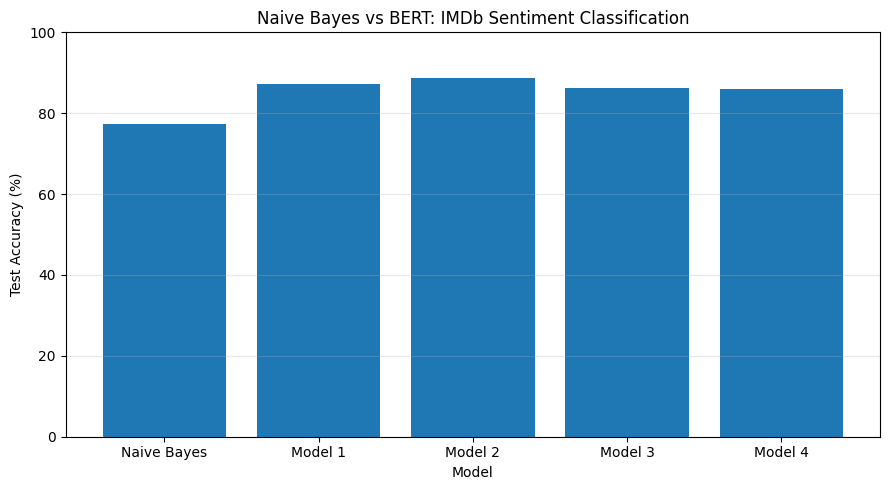


Improvement over Naive Bayes:
Model 1: +10.00 percentage points
Model 2: +11.50 percentage points
Model 3: +9.00 percentage points
Model 4: +8.75 percentage points

Comparison completed successfully.


In [66]:
# Naive Bayes vs BERT Performance Comparison


import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Assignment 1: Best Naive Bayes Scenario (Scenario 4)
# Confusion matrix from the submitted Assignment 1 report
#
# Rows: Actual Negative, Actual Positive
# Columns: Predicted Negative, Predicted Positive
# ------------------------------------------------------------

nb_confusion_matrix = np.array([
    [154, 46],
    [45, 155]
])

# Reconstruct labels from the confusion matrix
nb_y_true = np.array(
    [0] * 200 + [1] * 200
)

nb_y_pred = np.array(
    [0] * 154 +
    [1] * 46 +
    [0] * 45 +
    [1] * 155
)

# Calculate Naive Bayes classification metrics
nb_accuracy = accuracy_score(nb_y_true, nb_y_pred)

nb_precision, nb_recall, nb_f1, _ = (
    precision_recall_fscore_support(
        nb_y_true,
        nb_y_pred,
        labels=[0, 1],
        average="macro",
        zero_division=0
    )
)

# ------------------------------------------------------------
# Combine Naive Bayes with existing BERT results
# ------------------------------------------------------------

nb_row = pd.DataFrame([{
    "Model": "Naive Bayes",
    "Architecture": "Scenario 4",
    "Test Accuracy": nb_accuracy,
    "Macro Precision": nb_precision,
    "Macro Recall": nb_recall,
    "Macro F1": nb_f1
}])

bert_rows = comparison_df[
    [
        "Model",
        "Architecture",
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]
].copy()

final_comparison_df = pd.concat(
    [nb_row, bert_rows],
    ignore_index=True
)

print("=" * 65)
print("NAIVE BAYES VS BERT: TEST PERFORMANCE")
print("=" * 65)

display(final_comparison_df.round(4))

# ------------------------------------------------------------
# Compare accuracy
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Test Accuracy"] * 100
)

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.title("Naive Bayes vs BERT: IMDb Sentiment Classification")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Report improvement over Naive Bayes
# ------------------------------------------------------------

print("\nImprovement over Naive Bayes:")

for _, row in bert_rows.iterrows():

    improvement = (
        row["Test Accuracy"] - nb_accuracy
    ) * 100

    print(
        f"{row['Model']}: "
        f"{improvement:+.2f} percentage points"
    )

print("\nComparison completed successfully.")

### Computational Cost Comparison

In addition to classification performance, computational cost is an important consideration when comparing Naïve Bayes and BERT.

Naïve Bayes estimates class probabilities from word frequencies, whereas BERT fine-tunes a pretrained transformer containing approximately 109 million parameters.

The BERT models were trained on CPU hardware, and their training and inference times were measured during execution.

The original Assignment 1 implementation did not record separate training and inference times. Therefore, a direct numerical timing comparison with Naïve Bayes is not available.

The measured BERT training and inference times are reported below. Computational differences between the two approaches are discussed in terms of model complexity, hardware requirements, and training procedures.

COMPUTATIONAL COST COMPARISON


,Model,Training + Val Time (min),Inference Time (s),Time per Review (s)
0,Naive Bayes,NaN,NaN,NaN
1,Model 1,98.5818,268.7337,0.6718
2,Model 2,123.7900,218.5808,0.5465
3,Model 3,144.1454,224.5602,0.5614
4,Model 4,108.0531,229.9344,0.5748



Note:
Naive Bayes timing was not recorded in Assignment 1.
Missing values indicate unavailable measurements.


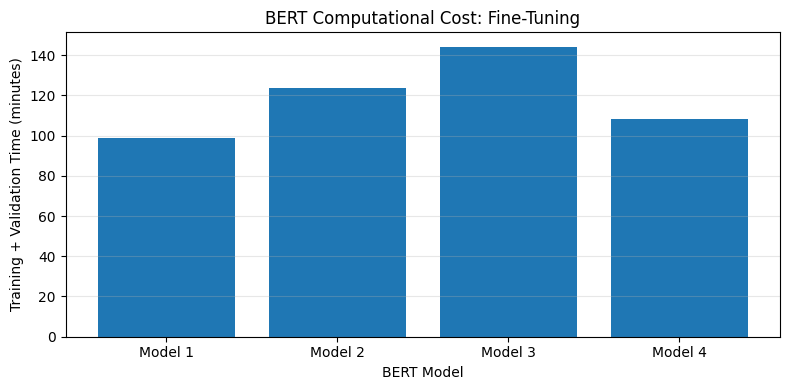

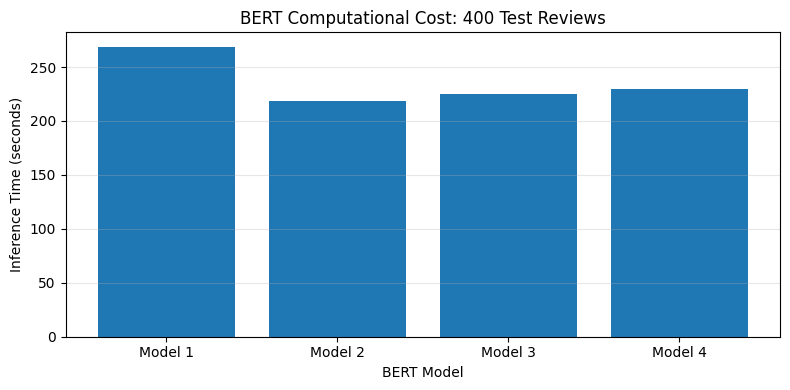


Computational cost analysis completed.


In [67]:
# Computational Cost Comparison
# Uses existing measured timing results only.


import pandas as pd
import matplotlib.pyplot as plt

# Build the timing comparison from measured BERT results
timing_comparison_df = comparison_df[
    [
        "Model",
        "Training + Val Time (min)",
        "Inference Time (s)",
        "Time per Review (s)"
    ]
].copy()

# Assignment 1 did not record separate timing measurements.
# Use missing values rather than inventing results.
nb_timing = pd.DataFrame([{
    "Model": "Naive Bayes",
    "Training + Val Time (min)": float("nan"),
    "Inference Time (s)": float("nan"),
    "Time per Review (s)": float("nan")
}])

timing_comparison_df = pd.concat(
    [nb_timing, timing_comparison_df],
    ignore_index=True
)

print("=" * 65)
print("COMPUTATIONAL COST COMPARISON")
print("=" * 65)

display(timing_comparison_df.round(4))

print("\nNote:")
print("Naive Bayes timing was not recorded in Assignment 1.")
print("Missing values indicate unavailable measurements.")

# ------------------------------------------------------------
# Plot 1: BERT Training and Validation Time
# ------------------------------------------------------------

bert_timing_df = timing_comparison_df[
    timing_comparison_df["Model"] != "Naive Bayes"
]

plt.figure(figsize=(8, 4))

plt.bar(
    bert_timing_df["Model"],
    bert_timing_df["Training + Val Time (min)"]
)

plt.xlabel("BERT Model")
plt.ylabel("Training + Validation Time (minutes)")
plt.title("BERT Computational Cost: Fine-Tuning")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot 2: BERT Test Inference Time
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

plt.bar(
    bert_timing_df["Model"],
    bert_timing_df["Inference Time (s)"]
)

plt.xlabel("BERT Model")
plt.ylabel("Inference Time (seconds)")
plt.title("BERT Computational Cost: 400 Test Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nComputational cost analysis completed.")


### Discussion: Naïve Bayes vs BERT

All four fine-tuned BERT models outperformed the best Naïve Bayes classifier from Assignment 1 on the 400 test reviews.

The best Naïve Bayes model, using lemmatization, stop-word removal, and logical negation handling, achieved 77.25% test accuracy and a macro F1-score of approximately 0.7725.

Among the BERT models, Model 2, with a 256-neuron ReLU classification head, achieved the highest test accuracy of 88.75% and macro F1-score of 0.8875. This represents an improvement of 11.50 percentage points over Naïve Bayes.

Model 1 achieved 87.25% test accuracy, while Models 3 and 4 achieved 86.25% and 86.00%, respectively.

Model 4 achieved the highest validation accuracy of 91.50%, but its test accuracy was 86.00%. Although averaging the [CLS] representations from the final four transformer blocks improved validation performance, this advantage did not generalize to the test dataset.

The results suggest that BERT's contextual representations are more effective for sentiment classification than the word-frequency-based approach used by Naïve Bayes. Unlike Naïve Bayes, which assumes conditional independence between words, BERT uses self-attention to represent words in context.

However, improved accuracy comes with greater computational cost. Fine-tuning each BERT model required approximately 99–144 minutes on CPU hardware, while test inference required approximately 219–269 seconds for 400 reviews.

The original Naïve Bayes assignment did not include timing measurements, so a direct numerical comparison of computational speed is unavailable. Nevertheless, Naïve Bayes has a substantially simpler model structure and does not require transformer fine-tuning.

The comparison also has limitations. Assignment 1 used 1,000 training reviews, whereas Assignment 4 used 800 training reviews and 200 validation reviews. In addition, the Naïve Bayes preprocessing scenario was selected using test performance, while BERT checkpoint and architecture selection used validation results.

Overall, BERT achieved better classification performance in this experiment, while Naïve Bayes remains a simpler approach with lower expected computational requirements.


## Conclusion

This assignment investigated four BERT-based architectures for binary sentiment classification of IMDb movie reviews.

The first three models used different classification heads: a linear layer, a ReLU hidden layer, and a GELU hidden layer. The fourth model averaged [CLS] representations from the final four BERT transformer blocks and used the linear classification head selected from the first three models.

Model 4 achieved the highest validation accuracy of 91.50%, while Model 2 achieved the highest observed test accuracy of 88.75%.

These results demonstrate that higher validation accuracy does not always translate into better test performance. Increasing classification-head complexity or combining representations from multiple transformer layers does not guarantee improved generalization.

Compared with the best Naïve Bayes classifier from Assignment 1, all four BERT models achieved higher test accuracy, with improvements ranging from 8.75 to 11.50 percentage points.

The main trade-off was computational cost. BERT required substantial fine-tuning and inference time on CPU hardware.

The findings highlight the importance of validation-based model selection, evaluation on independent test data, and considering both predictive performance and computational efficiency.


---
## Submission, reproducibility, and interpretation

**What is submitted:** this `.ipynb` with source code, explanatory Markdown, executed training outputs and figures; plus a separate PDF report (maximum four pages). The `saved_models/` checkpoints are *not* embedded in the notebook and are not needed to inspect the recorded outputs. Running this notebook from scratch requires `movie.csv` and downloading/caching the Hugging Face base model; it regenerates checkpoints as part of training.

**Selection vs. evaluation:** Model 4 was selected from validation data (91.50% validation accuracy). Model 2 gave the highest observed test accuracy (88.75%), but was not retroactively chosen using the test set. Small validation/test sets make differences uncertain.

**Naïve Bayes comparison:** Assignment 1 Scenario 4 confusion-matrix counts were taken from the previously submitted PDF, rather than rerunning Naïve Bayes. Thus the reconstructed labels are only used to reproduce *aggregate metrics*; they cannot support review-by-review paired error analysis. Assignment 1 used 1,000 training examples while the BERT models used 800 training examples and 200 validation examples. Direct Naïve Bayes time measurements were not recorded; missing times are deliberately shown as unavailable.

**Environment:** PyTorch CPU evaluation, `bert-base-uncased`, 384 tokens maximum, batch size 8, three training epochs, AdamW (learning rate `2e-5`, weight decay `0.01`), fixed sampling seed 42.
